# SP-buy Fraud Detection — Random Forest

**Author:** Abby  
**Module:** ST1519 Agile MLOps  
**Project:** CA1 — SP-buy Fraud Detection

## 1. Introduction and Objective

This notebook evaluates Random Forest for binary fraud classification using two feature datasets:

- Version 1 (Safe): 31 prediction features.
- Version 2 (Full): 41 prediction features.

The objective is to achieve high precision while maintaining reasonable recall, in accordance with the stakeholder's business requirements.

Both versions use the same chronological training, validation and testing boundaries to ensure a fair comparison.

Random Forest was selected as a non-linear ensemble learning algorithm that can capture complex fraud patterns and feature interactions that may not be adequately represented by Logistic Regression.

### 1.1 Algorithm Selection and Justification

Random Forest combines multiple decision trees trained using bootstrap sampling and random feature selection. The final fraud probability is obtained by averaging the predicted probabilities across the trees.

Random Forest is suitable for SP-buy fraud detection for the following reasons:

- **Non-linear modelling:** Captures complex relationships between customer characteristics, order information and fraud risk.
- **Feature interactions:** Identifies combinations of features without requiring manually specified interaction terms.
- **Reduced variance:** Combines multiple decision trees to reduce the risk of overfitting compared with a single decision tree.
- **Minimal preprocessing:** Does not require feature standardisation.
- **Feature importance:** Supports investigation of influential fraud predictors.
- **Class imbalance handling:** Supports class weighting as a potential strategy to improve fraud detection coverage.

However, Random Forest may require greater training time, memory and model storage than Logistic Regression.

Therefore, predictive performance, generalisation and computational efficiency will be considered during model development.

## 2. Import Libraries and Configuration

Import the required libraries and reuse the shared data split
and MLflow logging utilities to ensure consistency across
all team members.

Random Forest does not require feature standardisation,
as decision trees perform splits based on individual
feature values.

The same random seed and initial decision threshold used
in the Logistic Regression experiments are retained to
support consistent and reproducible model comparison.

In [1]:
from pathlib import Path
import sys
import os
import time

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestClassifier

# Locate the repository root
PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

sys.path.insert(0, str(PROJECT_ROOT))

# Shared team modules
from src.data_split import create_split_labels

from src.mlflow_utils import (
    connect_mlflow,
    start_model_run,
    log_model_parameters,
    log_classification_metrics,
    log_trained_model,
    log_evaluation_artifacts
)

# Configuration
DATA_DIR = PROJECT_ROOT / "data" / "processed"

RANDOM_STATE = 42
THRESHOLD = 0.5
TARGET = "is_fraud"

print("Python version:", sys.version.split()[0])
print("Project root:", PROJECT_ROOT)
print("Data directory:", DATA_DIR)

Python version: 3.13.9
Project root: c:\Users\User\OneDrive - Singapore Polytechnic\Desktop\MLOps_CA1_group5
Data directory: c:\Users\User\OneDrive - Singapore Polytechnic\Desktop\MLOps_CA1_group5\data\processed


## 3. Load Shared Feature Datasets

Load the preprocessed Safe and Full datasets prepared
during PBI 1.

Both datasets contain the same orders and fraud labels.
The Safe dataset excludes 10 customer snapshot features
whose availability at prediction time is uncertain.

The Full dataset is used for exploratory comparison to
evaluate the potential impact of these additional features.

The same datasets used in the Logistic Regression
experiments are retained to ensure consistent comparison
between the two algorithms.

No additional data cleaning or feature engineering is
performed in this notebook.

In [2]:
df_safe = pd.read_csv(
    DATA_DIR / "features_base_safe.csv",
    dtype={
        "country_code": str,
        "order_id": str,
        "customer_id": str
    },
    parse_dates=["order_date"]
)

df_full = pd.read_csv(
    DATA_DIR / "features_base_full.csv",
    dtype={
        "country_code": str,
        "order_id": str,
        "customer_id": str
    },
    parse_dates=["order_date"]
)

dataset_summary = pd.DataFrame({
    "Dataset": ["Safe", "Full"],
    "Records": [len(df_safe), len(df_full)],
    "Total Columns": [
        df_safe.shape[1],
        df_full.shape[1]
    ],
    "Missing Values": [
        df_safe.isna().sum().sum(),
        df_full.isna().sum().sum()
    ]
})

display(dataset_summary)

,Dataset,Records,Total Columns,Missing Values
0,Safe,949872,36,0
1,Full,949872,46,0


**Observations:**

- Both datasets contain 949,872 records, consistent with
  the datasets used in the Logistic Regression experiments.
- The Safe dataset contains 36 columns, while the Full
  dataset contains 46 columns.
- Both datasets contain no missing values.
- The Full dataset contains 10 additional customer snapshot
  features for exploratory comparison.
- Further validation is required to confirm that both
  datasets contain identical orders, labels and shared
  feature values.

### 3.1 Dataset Understanding

Examine the column names and data types of both datasets
to understand the available model inputs.

Detailed dataset exploration was previously performed
during PBI 1 and the Logistic Regression experiments.

Therefore, this section focuses on confirming the dataset
structure required for Random Forest model development,
without repeating unnecessary exploratory analysis.

In [3]:
column_summary = pd.DataFrame({
    "Column": df_full.columns,
    "Data Type": df_full.dtypes.astype(str).values,
    "In Safe Dataset": [
        column in df_safe.columns
        for column in df_full.columns
    ],
    "In Full Dataset": True
})

display(column_summary)

,Column,Data Type,In Safe Dataset,In Full Dataset
0,country_code,object,True,True
1,order_id,object,True,True
2,customer_id,object,True,True
3,order_date,datetime64[ns],True,True
4,value_per_item,float64,True,True
5,cancel_rate,float64,False,True
6,refund_rate,float64,False,True
7,avg_payment_per_order,float64,False,True
8,first_order_missing,int64,True,True
9,account_age_invalid,int64,True,True


**Observations:**

- Both datasets contain the same expected column structure
  as the datasets used in the Logistic Regression experiments.
- The Full dataset contains 10 additional customer snapshot
  features, including refund behaviour, cancellation behaviour,
  historical payments and associated customer information.
- All prediction features are represented using numerical
  data types (`int64` or `float64`).
- Country, collection type and payment method categories
  have already been encoded during PBI 1.
- The order date is correctly represented as `datetime64[ns]`,
  supporting chronological data splitting.
- The prepared numerical features can be used directly for
  Random Forest without additional encoding or standardisation.

## 4. Data Validation

Before model training, both datasets are validated to ensure:

- Identical order records and fraud labels.
- No missing values.
- No duplicate orders.
- Valid binary target labels (0 and 1).
- No duplicate column names.
- Exclusion of the prohibited refund_value column.

These checks ensure that both Random Forest versions
are developed using consistent and valid order records.

The same validation approach used in the Logistic
Regression experiments is retained to ensure consistency
across both algorithms.

Numerical feature values and shared feature consistency
will be further validated during feature preparation.

In [4]:
# Columns used to identify and align records
ID_COLUMNS = [
    "country_code",
    "order_id",
    "customer_id",
    "order_date"
]

# Verify identical records and target labels
assert df_safe[ID_COLUMNS].equals(
    df_full[ID_COLUMNS]
), "Dataset records are inconsistent."

assert df_safe[TARGET].equals(
    df_full[TARGET]
), "Target labels are inconsistent."

# Validate both datasets
for name, df in [
    ("Safe", df_safe),
    ("Full", df_full)
]:
    assert not df.isna().any().any(), (
        f"{name}: Missing values detected."
    )

    assert not df.duplicated(
        ["country_code", "order_id"]
    ).any(), f"{name}: Duplicate orders detected."

    assert set(df[TARGET].unique()) == {0, 1}, (
        f"{name}: Invalid target labels."
    )

    assert "refund_value" not in df.columns, (
        f"{name}: Prohibited refund_value column detected."
    )

    assert df.columns.is_unique, (
        f"{name}: Duplicate column names detected."
    )

    print(f"{name} dataset validation passed.")

print("\nBoth datasets contain identical records and labels.")

Safe dataset validation passed.
Full dataset validation passed.

Both datasets contain identical records and labels.


**Observations:**

- Both datasets successfully passed all validation checks.
- The Safe and Full datasets contain identical order
  records and fraud labels in the same row order.
- No missing values or duplicate order keys were detected.
- Both datasets contain valid binary fraud labels (0 and 1).
- No duplicate column names were detected.
- The prohibited refund_value column is absent from
  both datasets.

These results confirm that both datasets contain
consistent order records and valid target labels,
supporting a controlled comparison between the
Safe and Full Random Forest versions.

## 5. Feature and Target Preparation

Separate the prediction features from identifiers,
order dates and the target variable.

Raw identifiers and order dates are excluded from the
model inputs. The order date is retained separately
for chronological data splitting.

The target variable is is_fraud:

- 0: Non-fraudulent order
- 1: Fraudulent order

The same prediction features used in the Logistic
Regression experiments are retained to ensure a fair
comparison between the two algorithms.

Unlike Logistic Regression, Random Forest can use
the prepared numerical features directly without
feature standardisation.

In [5]:
# Columns excluded from prediction features
EXCLUDE_COLUMNS = ID_COLUMNS + [TARGET]

# Separate features and target
X_safe = df_safe.drop(columns=EXCLUDE_COLUMNS)
X_full = df_full.drop(columns=EXCLUDE_COLUMNS)

y = df_safe[TARGET].astype(int)

# Verify feature counts
assert X_safe.shape[1] == 31
assert X_full.shape[1] == 41

# Verify Safe features are a subset of Full features
assert set(X_safe.columns).issubset(X_full.columns)

# Verify common feature values are identical
assert X_safe.equals(X_full[X_safe.columns])

# Check all features are numerical and finite
for name, X in [
    ("Safe", X_safe),
    ("Full", X_full)
]:
    assert X.select_dtypes(
        include="number"
    ).shape[1] == X.shape[1], (
        f"{name}: Non-numerical features detected."
    )

    assert np.isfinite(X.to_numpy()).all(), (
        f"{name}: Infinite or missing values detected."
    )

# Identify additional Full dataset features
additional_features = [
    column for column in X_full.columns
    if column not in X_safe.columns
]

print("Safe feature shape:", X_safe.shape)
print("Full feature shape:", X_full.shape)
print("Target shape:", y.shape)

print("\nAdditional features in Full dataset:")

for i, feature in enumerate(additional_features, 1):
    print(f"{i}. {feature}")

Safe feature shape: (949872, 31)
Full feature shape: (949872, 41)
Target shape: (949872,)

Additional features in Full dataset:
1. cancel_rate
2. refund_rate
3. avg_payment_per_order
4. mobile_verified
5. associated_capped
6. log_num_orders_last_50days
7. log_num_cancelled_orders_last_50days
8. log_num_refund_orders_last_50days
9. log_total_payment_last_50days
10. log_num_associated_customers


In [6]:
from src.data_processing import SNAPSHOT_FEATURES

assert set(additional_features) == set(SNAPSHOT_FEATURES), (
    "Unexpected differences between Safe and Full datasets."
)

print("Feature sets match the team's approved definitions.")

Feature sets match the team's approved definitions.


**Observations:**

- The Safe dataset contains 31 prediction features,
  while the Full dataset contains 41 prediction features.
- Both feature datasets contain 949,872 records and
  share the same binary target variable.
- All 31 Safe features are present in the Full dataset
  with identical feature values.
- All prediction features are numerical and finite.
- Identifiers, order dates and the target variable
  have been excluded from the model inputs.
- The 10 additional customer snapshot features in the
  Full dataset are retained for exploratory comparison.

The consistent feature definitions and target labels
support a controlled comparison between both Random
Forest versions and the previously developed Logistic
Regression models.

No feature standardisation is required for Random Forest.
However, the uncertain point-in-time availability of
the additional Full features remains a potential
temporal data leakage concern.

## 6. Shared Chronological Data Split

The shared chronological splitting function from
src/data_split.py is used to ensure consistency
across all team members and model versions.

The chronological boundaries are:

- Training: Up to 15 March 2023
- Validation: 16 March 2023 to 13 April 2023
- Testing: 14 April 2023 onwards

A chronological split better reflects real-world fraud
detection, where models are trained on historical orders
and evaluated on subsequent orders.

The same chronological boundaries used in the Logistic
Regression experiments are retained to ensure fair
comparison between the two algorithms.

The validation set is used for performance diagnosis
and model selection, while the test set is reserved
for final evaluation.

### 6.1 Apply Shared Chronological Split

In [7]:
# Apply the team's shared chronological split
split_labels = create_split_labels(df_safe)

# Verify the same split applies to Full dataset
assert split_labels.equals(
    create_split_labels(df_full)
)

# Create split masks
train_mask = split_labels == "Train"
val_mask = split_labels == "Validation"
test_mask = split_labels == "Test"

# Summarise split distribution
split_summary = pd.DataFrame({
    "Split": ["Train", "Validation", "Test"],
    "Records": [
        train_mask.sum(),
        val_mask.sum(),
        test_mask.sum()
    ],
    "Fraud Cases": [
        y[train_mask].sum(),
        y[val_mask].sum(),
        y[test_mask].sum()
    ],
})

split_summary["Percentage (%)"] = (
    split_summary["Records"] / len(y) * 100
).round(2)

split_summary["Fraud Rate (%)"] = (
    split_summary["Fraud Cases"] /
    split_summary["Records"] * 100
).round(4)

display(split_summary)

# Verify complete split coverage
assert split_summary["Records"].sum() == len(y)

# Verify each split contains both target classes
for mask in [train_mask, val_mask, test_mask]:
    assert set(y[mask].unique()) == {0, 1}

print("Shared chronological split verified.")

,Split,Records,Fraud Cases,Percentage (%),Fraud Rate (%)
0,Train,665876,67594,70.10,10.1511
1,Validation,139874,18993,14.73,13.5786
2,Test,144122,17835,15.17,12.3749


Shared chronological split verified.


### 6.2 Fraud Distribution Across Chronological Splits

The fraud rates across the training, validation and
test sets are visualised to examine changes in class
distribution over time.

Understanding these differences is important because
Random Forest may be affected by class imbalance and
changes in fraud prevalence across chronological periods.

The test distribution is reported for descriptive
purposes only and is not used for hyperparameter
or threshold selection.

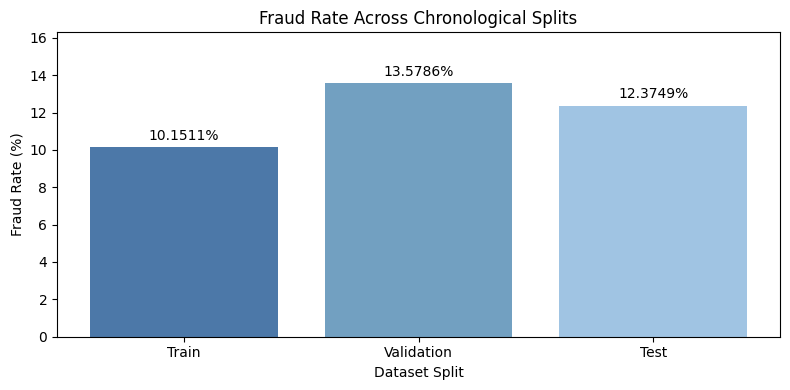

In [8]:
fig, ax = plt.subplots(figsize=(8, 4))

bars = ax.bar(
    split_summary["Split"],
    split_summary["Fraud Rate (%)"],
    color=["#4C78A8", "#72A0C1", "#A0C4E3"]
)

ax.bar_label(bars, fmt="%.4f%%", padding=3)

ax.set_title("Fraud Rate Across Chronological Splits")
ax.set_xlabel("Dataset Split")
ax.set_ylabel("Fraud Rate (%)")

ax.set_ylim(
    0,
    split_summary["Fraud Rate (%)"].max() * 1.2
)

plt.tight_layout()
plt.show()

**Observations:**

- The chronological split contains 665,876 training,
  139,874 validation and 144,122 test records.
- All 949,872 records are assigned to one of the three
  chronological splits.
- Both fraud and non-fraud classes are present in
  every split.
- The training set has a fraud rate of 10.1511%,
  indicating a substantial class imbalance.
- The validation and test sets have higher fraud rates
  of 13.5786% and 12.3749%, respectively.
- These differences indicate changes in class prevalence
  across chronological periods.
- The split distribution is identical to that used in
  the Logistic Regression experiments.

**Implications for Random Forest:**

- Accuracy alone is insufficient for evaluating
  fraud detection performance.
- Precision, recall, F1-score, Average Precision and
  ROC-AUC should be considered.
- Class weighting may be investigated to improve
  minority-class detection.
- Model complexity and classification thresholds
  should be assessed using validation performance
  before final test evaluation.

## 7. Model-specific Exploratory Data Analysis

This section focuses on data characteristics relevant
to Random Forest model development.

Detailed exploratory data analysis was previously
performed during PBI 1 and the Logistic Regression
experiments.

Unlike Logistic Regression, Random Forest does not
require feature standardisation and is less directly
affected by multicollinearity.

Therefore, the analysis focuses on class imbalance
and feature variability to support model configuration.

Only training data is used for model-specific
exploratory analysis.

### 7.1 Training Set Class Distribution

Examine the distribution of fraudulent and non-fraudulent
orders in the training dataset.

Class imbalance may cause Random Forest to favour the
majority class, resulting in limited fraud detection
coverage despite high overall accuracy.

The analysis supports decisions regarding class
weighting and appropriate evaluation metrics.

,Class,Records,Percentage (%)
0,Non-fraud,598282,89.8489
1,Fraud,67594,10.1511


Class imbalance ratio: 8.85:1


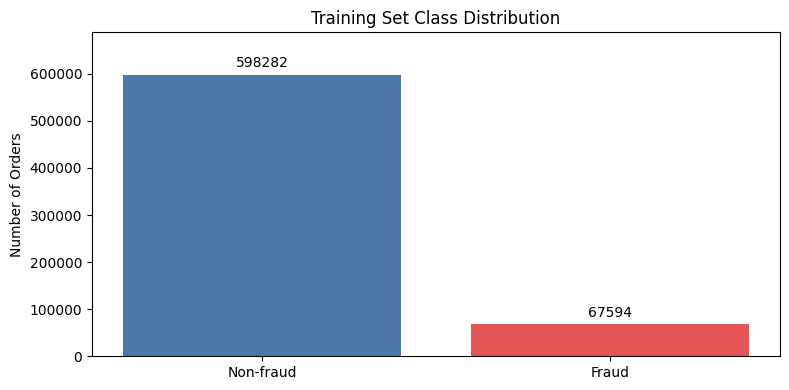

In [9]:
# Training target distribution
train_class_counts = (
    y[train_mask]
    .value_counts()
    .sort_index()
)

train_class_summary = pd.DataFrame({
    "Class": ["Non-fraud", "Fraud"],
    "Records": train_class_counts.values,
    "Percentage (%)": (
        train_class_counts.values /
        train_mask.sum() * 100
    ).round(4)
})

display(train_class_summary)

# Calculate imbalance ratio
imbalance_ratio = (
    train_class_counts.loc[0] /
    train_class_counts.loc[1]
)

print(f"Class imbalance ratio: {imbalance_ratio:.2f}:1")

# Visualise class distribution
fig, ax = plt.subplots(figsize=(8, 4))

bars = ax.bar(
    train_class_summary["Class"],
    train_class_summary["Records"],
    color=["#4C78A8", "#E45756"]
)

ax.bar_label(bars, fmt="%.0f", padding=3)

ax.set_title("Training Set Class Distribution")
ax.set_ylabel("Number of Orders")
ax.set_ylim(0, train_class_counts.max() * 1.15)

plt.tight_layout()
plt.show()

**Observations:**

- The training dataset contains 598,282 non-fraudulent
  orders and 67,594 fraudulent orders.
- Fraudulent orders account for approximately 10.15%
  of the training dataset.
- The class imbalance ratio is approximately 8.85:1.
- A model that predicts every order as non-fraudulent
  could achieve approximately 89.85% accuracy while
  failing to detect any fraudulent orders.

**Implications for Random Forest:**

- Accuracy should not be used as the sole evaluation metric.
- Precision and recall are particularly important for
  evaluating fraud detection performance.
- Class weighting may improve minority-class detection,
  but its impact on false positives must be considered.
- The original class distribution is retained to ensure
  consistent comparison with Logistic Regression.

### 7.2 Feature Variability Analysis

Random Forest constructs decision trees by selecting
features and split thresholds that improve class
separation.

Features with constant values cannot contribute to
decision tree splitting, while features with different
values may provide useful splitting opportunities.

The number of unique values is examined using training
data to identify constant, binary and other numerical
features.

The existing feature definitions are retained to ensure
consistency across the Safe and Full experiments and
with Logistic Regression.

In [10]:
# Analyse feature variability using training data only
feature_variability = pd.DataFrame({
    "Feature": X_full.columns,
    "Unique Values": (
        X_full.loc[train_mask]
        .nunique()
        .values
    ),
    "Feature Set": [
        "Shared" if feature in X_safe.columns
        else "Full-only"
        for feature in X_full.columns
    ]
})

# Categorise feature variability
feature_variability["Feature Type"] = np.select(
    [
        feature_variability["Unique Values"] == 1,
        feature_variability["Unique Values"] == 2
    ],
    [
        "Constant",
        "Binary"
    ],
    default="Other numerical"
)

display(feature_variability)

# Summarise feature types
feature_type_summary = pd.crosstab(
    feature_variability["Feature Set"],
    feature_variability["Feature Type"],
    margins=True,
    margins_name="Total"
)

display(feature_type_summary)

# Identify constant features
constant_features = feature_variability.loc[
    feature_variability["Feature Type"] == "Constant",
    "Feature"
].tolist()

print("Constant features:", constant_features)

,Feature,Unique Values,Feature Set,Feature Type
0,value_per_item,420915,Shared,Other numerical
1,cancel_rate,1525,Full-only,Other numerical
2,refund_rate,1574,Full-only,Other numerical
3,avg_payment_per_order,441874,Full-only,Other numerical
4,first_order_missing,2,Shared,Binary
5,account_age_invalid,2,Shared,Binary
6,account_age_days,3736,Shared,Other numerical
7,mobile_verified,2,Full-only,Binary
8,associated_capped,2,Full-only,Binary
9,log_order_value,357565,Shared,Other numerical


Feature Type,Binary,Constant,Other numerical,Total
Feature Set,,,,
Full-only,2,0,8,10
Shared,26,1,4,31
Total,28,1,12,41


Constant features: ['payment_method_other']


**Observations:**

- Among the 41 Full dataset features, 28 are binary,
  12 contain more than two unique numerical values,
  and one is constant.

- The Safe dataset contains 26 binary features,
  four other numerical features and one constant feature.

- The 10 additional Full-only features consist of
  two binary features and eight other numerical features.

- Several numerical features contain a large number
  of unique values:
  - log_total_payment_last_50days: 453,274
  - avg_payment_per_order: 441,874
  - value_per_item: 420,915
  - log_order_value: 357,565

- payment_method_other is the only constant feature
  in the training dataset.

**Implications for Random Forest:**

- Numerical features with many unique values provide
  numerous potential decision tree splitting points.
- Tree complexity should be controlled to reduce
  overfitting and computational costs.
- Impurity-based feature importance may favour
  features with many possible splitting points.
- The constant feature cannot contribute to tree
  splitting but is retained to maintain the team's
  consistent feature schema.
- No feature standardisation or additional categorical
  encoding is required.

### 7.3 Feature Characteristics and Model Implications

| Data Characteristic | Implication for Random Forest |
|---|---|
| Different numerical feature scales | Feature standardisation is not required. |
| One-hot encoded categorical features | Can be used directly for decision tree splitting. |
| Class imbalance | Class weighting and decision thresholds may be investigated. |
| Correlated features | Less problematic for model fitting, but feature importance may be distributed across correlated predictors. |
| Constant features | Cannot contribute to decision tree splitting. |
| Potential non-linear relationships | Random Forest can capture non-linear patterns and feature interactions. |
| Large training dataset | Tree complexity and computational efficiency must be considered. |
| Additional customer snapshot features | Full dataset remains exploratory due to potential temporal data leakage. |

Based on these considerations, Random Forest model
development will focus on predictive performance,
tree complexity, generalisation and computational
efficiency.

No additional feature transformation or resampling
is performed.

## 8. Model Configuration

Random Forest is implemented using the scikit-learn
RandomForestClassifier.

Both the Safe and Full versions use the same
hyperparameter configuration to support a controlled
comparison of the two feature sets.

### 8.1 Random Forest Hyperparameters

| Hyperparameter | Value | Justification |
|---|---|---|
| n_estimators | 50 | Provides an initial balance between ensemble diversity and computational efficiency. |
| criterion | gini | Measures impurity when evaluating decision tree splits. |
| max_depth | 15 | Limits tree complexity and reduces potential overfitting. |
| min_samples_split | 10 | Prevents further splitting of nodes containing very few samples. |
| min_samples_leaf | 20 | Encourages more generalisable decision rules by requiring sufficient samples in each leaf. |
| max_features | sqrt | Introduces feature randomness to reduce correlation between trees. |
| bootstrap | True | Trains individual trees using bootstrap samples. |
| class_weight | None | Retains the original class weighting for the baseline experiments. |
| random_state | 42 | Supports reproducible model development. |
| n_jobs | -1 | Enables parallel processing across available CPU cores. |

A decision threshold of 0.5 is retained for both
versions to support consistent baseline comparison
with Logistic Regression.

Feature standardisation is not required because
Random Forest uses tree-based splitting rules.

These hyperparameters represent an initial,
complexity-controlled configuration rather than
an experimentally optimised configuration.

Further improvements will be considered based on
validation performance and computational efficiency.

In [11]:
MODEL_PARAMS = {
    "n_estimators": 50,
    "criterion": "gini",
    "max_depth": 15,
    "min_samples_split": 10,
    "min_samples_leaf": 20,
    "max_features": "sqrt",
    "bootstrap": True,
    "class_weight": None,
    "random_state": RANDOM_STATE,
    "n_jobs": -1
}


def build_random_forest():
    return RandomForestClassifier(
        **MODEL_PARAMS
    )


# Display model configuration
parameter_summary = pd.DataFrame({
    "Hyperparameter": list(MODEL_PARAMS.keys()),
    "Value": list(MODEL_PARAMS.values())
})

display(parameter_summary)

,Hyperparameter,Value
0,n_estimators,50
1,criterion,gini
2,max_depth,15
3,min_samples_split,10
4,min_samples_leaf,20
5,max_features,sqrt
6,bootstrap,True
7,class_weight,None
8,random_state,42
9,n_jobs,-1


### 8.2 MLflow Experiment Tracking Configuration

The team's shared MLflow logging utilities are reused
to maintain consistent experiment tracking across
different fraud detection algorithms.

During model development, experiments are logged to
the persistent local MLflow server.

The same experiment name and logging conventions used
in the Logistic Regression experiments are retained.

Shared AWS MLflow integration will be completed under
the relevant infrastructure and experiment tracking PBIs.

In [12]:
import mlflow

# Read the tracking endpoint from external configuration.
configured_tracking_uri = os.environ.get("MLFLOW_TRACKING_URI")

if not configured_tracking_uri:
    raise ValueError(
        "MLFLOW_TRACKING_URI is not configured. "
        "Set the environment variable before running this notebook."
    )

EXPERIMENT_NAME = "SP-buy-Fraud-Detection"

# Prevent accidental logging to a different server

connect_mlflow(
    experiment_name=EXPERIMENT_NAME
)

assert mlflow.get_tracking_uri() == configured_tracking_uri, (
    "The active MLflow tracking URI does not match "
    "the configured tracking endpoint."
)

print("MLflow tracking URI:", mlflow.get_tracking_uri())
print("Experiment name:", EXPERIMENT_NAME)

MLflow Tracking URI: http://127.0.0.1:5004
Experiment: SP-buy-Fraud-Detection
MLflow tracking URI: http://127.0.0.1:5004
Experiment name: SP-buy-Fraud-Detection


## 9. Version 1 — Random Forest (Safe Dataset)

### 9.1 Training Data Preparation

Version 1 uses the Safe dataset containing 31 prediction
features.

The restricted feature set excludes customer snapshot
features whose availability at prediction time has not
been confirmed.

The shared chronological split is retained to ensure
consistent evaluation across all team models.

The prepared numerical features are used directly
without standardisation or additional transformation.

In [13]:
X_train_safe = X_safe.loc[train_mask]
X_val_safe = X_safe.loc[val_mask]
X_test_safe = X_safe.loc[test_mask]

y_train = y.loc[train_mask]
y_val = y.loc[val_mask]
y_test = y.loc[test_mask]

safe_split_summary = pd.DataFrame({
    "Split": ["Train", "Validation", "Test"],
    "Records": [
        len(X_train_safe),
        len(X_val_safe),
        len(X_test_safe)
    ],
    "Features": [
        X_train_safe.shape[1],
        X_val_safe.shape[1],
        X_test_safe.shape[1]
    ],
    "Fraud Cases": [
        y_train.sum(),
        y_val.sum(),
        y_test.sum()
    ]
})

display(safe_split_summary)

,Split,Records,Features,Fraud Cases
0,Train,665876,31,67594
1,Validation,139874,31,18993
2,Test,144122,31,17835


### 9.2 Model Training

A Random Forest classifier is fitted using the Safe
training dataset.

The model combines 50 decision trees with controlled
tree depth and minimum leaf size to limit model
complexity and potential overfitting.

Training duration and tree complexity are recorded
to assess computational efficiency, generalisation
potential and suitability for automated retraining.

Only the training dataset is used to fit the model.

In [14]:
# Create the Safe Random Forest model
model_safe = build_random_forest()

# Record training time
start_time = time.perf_counter()

model_safe.fit(
    X_train_safe,
    y_train
)

training_time_safe = (
    time.perf_counter() - start_time
)

# Retrieve individual tree information
tree_depths_safe = [
    tree.get_depth()
    for tree in model_safe.estimators_
]

tree_leaves_safe = [
    tree.get_n_leaves()
    for tree in model_safe.estimators_
]

tree_nodes_safe = [
    tree.tree_.node_count
    for tree in model_safe.estimators_
]

# Summarise model complexity
mean_depth_safe = float(np.mean(tree_depths_safe))
max_depth_safe = int(np.max(tree_depths_safe))
mean_leaves_safe = float(np.mean(tree_leaves_safe))
total_nodes_safe = int(np.sum(tree_nodes_safe))

print("Model: Random Forest")
print("Version: V1 - Safe Dataset")
print("Training records:", len(X_train_safe))
print("Number of features:", X_train_safe.shape[1])
print(f"Training time: {training_time_safe:.4f} seconds")
print("Number of trees:", len(model_safe.estimators_))
print(f"Mean tree depth: {mean_depth_safe:.2f}")
print("Maximum tree depth:", max_depth_safe)
print(f"Mean leaf nodes: {mean_leaves_safe:.2f}")
print("Total tree nodes:", total_nodes_safe)

# Verify model configuration
assert len(model_safe.estimators_) == MODEL_PARAMS["n_estimators"]
assert max_depth_safe <= MODEL_PARAMS["max_depth"]
assert np.array_equal(model_safe.classes_, [0, 1])

print("Model configuration check: Passed")

Model: Random Forest
Version: V1 - Safe Dataset
Training records: 665876
Number of features: 31
Training time: 11.0171 seconds
Number of trees: 50
Mean tree depth: 15.00
Maximum tree depth: 15
Mean leaf nodes: 1096.24
Total tree nodes: 109574
Model configuration check: Passed


### Training Observations

- The Random Forest classifier was successfully trained
  on 665,876 orders using 31 prediction features.
- Model training took approximately 11.02 seconds.
- All 50 decision trees were successfully constructed.
- The mean and maximum tree depths were both 15,
  indicating that all trees reached the configured
  maximum depth.
- Each tree contains approximately 1,096 leaf nodes
  on average, with 109,574 nodes across the entire forest.
- All model configuration checks passed.
- The depth restriction successfully limits tree growth,
  although further evaluation is required to determine
  whether the current complexity is appropriate.

The training duration suggests that the model may be
suitable for automated retraining. However, the complete
pipeline execution time must be evaluated separately
under PBI 5.

Predictive performance must still be assessed before
determining whether the model satisfies the stakeholder's
fraud detection requirements.

### 9.3 Validation Predictions

The trained Random Forest model generates fraud
probabilities for the training and validation datasets.

A fixed decision threshold of 0.5 is used to convert
the predicted probabilities into binary classifications.

The same threshold used in the Logistic Regression
experiments is retained for baseline comparison.

Training and validation performance will be compared
to identify potential overfitting or underfitting.

The test dataset remains reserved for final evaluation.

In [15]:
# Generate fraud probabilities
y_train_prob_safe = model_safe.predict_proba(
    X_train_safe
)[:, 1]

y_val_prob_safe = model_safe.predict_proba(
    X_val_safe
)[:, 1]

# Convert probabilities into class predictions
y_val_pred_safe = (
    y_val_prob_safe >= THRESHOLD
).astype(int)

prediction_summary_safe = pd.DataFrame({
    "Actual": y_val.to_numpy(),
    "Fraud Probability": y_val_prob_safe,
    "Predicted": y_val_pred_safe
})

# Display aggregate probability statistics
display(
    prediction_summary_safe[
        "Fraud Probability"
    ].describe().to_frame()
)

print("Validation records:", len(y_val))
print("Actual fraud cases:", y_val.sum())
print("Predicted fraud cases:", y_val_pred_safe.sum())
print("Decision threshold:", THRESHOLD)

,Fraud Probability
count,139874.000000
mean,0.103944
std,0.119631
min,0.008598
25%,0.036233
50%,0.057052
75%,0.124721
max,0.801684


Validation records: 139874
Actual fraud cases: 18993
Predicted fraud cases: 3429
Decision threshold: 0.5


**Observations:**

- Fraud probabilities were generated for all 139,874
  validation records.
- The mean predicted fraud probability is approximately
  0.1039, while the median is approximately 0.0571.
- The predicted probabilities range from approximately
  0.0086 to 0.8017.
- At the fixed decision threshold of 0.5, Random Forest
  flags 3,429 orders as potentially fraudulent.
- The validation dataset contains 18,993 actual
  fraudulent orders.
- Compared with the Logistic Regression Safe model,
  which flagged 1,316 orders, Random Forest identifies
  a larger number of potential fraud cases.

However, a higher number of flagged orders does not
necessarily indicate better fraud detection performance,
as additional predictions may include false positives.

Precision, recall and confusion matrix analysis are
required to determine whether the increased detection
coverage benefits the stakeholder.

### 9.4 Evaluation and MLflow Experiment Logging

The shared MLflow logging utilities are used to record:

- Model hyperparameters and training configuration.
- Training duration and tree complexity information.
- Training and validation evaluation metrics.
- The trained Random Forest classifier and model signature.
- Confusion matrix and precision-recall curve.
- Prediction feature metadata.

Training and validation metrics are recorded to identify
potential overfitting or underfitting.

The same evaluation metrics and experiment naming
conventions used in the Logistic Regression experiments
are retained for consistent comparison.

The test dataset is reserved for final evaluation
after both model versions have been configured.

In [16]:
with start_model_run(
    member="abby",
    algorithm="random_forest",
    dataset_version="safe",
    model_version="v1"
) as run:

    run_id_safe = run.info.run_id

    # 1. Record model configuration
    log_model_parameters(
        model_params=MODEL_PARAMS,
        threshold=THRESHOLD,
        feature_count=X_train_safe.shape[1]
    )

    mlflow.log_params({
        "scaler": "None",
        "training_records": len(X_train_safe),
        "validation_records": len(X_val_safe)
    })

    # 2. Record computational performance
    mlflow.log_metrics({
        "training_time_seconds": training_time_safe,
        "mean_tree_depth": mean_depth_safe,
        "max_tree_depth": max_depth_safe,
        "mean_tree_leaves": mean_leaves_safe,
        "total_tree_nodes": total_nodes_safe
    })

    # 3. Record training metrics
    train_metrics_safe = log_classification_metrics(
        y_true=y_train,
        y_prob=y_train_prob_safe,
        threshold=THRESHOLD,
        split="train"
    )

    # 4. Record validation metrics
    val_metrics_safe = log_classification_metrics(
        y_true=y_val,
        y_prob=y_val_prob_safe,
        threshold=THRESHOLD,
        split="val"
    )

    # 5. Save trained Random Forest model
    model_info_safe = log_trained_model(
        model=model_safe,
        X_sample=X_train_safe.head(5),
        model_name="random_forest_safe",
        skops_trusted_types=[
            "sklearn.tree._tree.Tree"
        ]
    )

    # 6. Save evaluation artifacts
    log_evaluation_artifacts(
        y_true=y_val,
        y_prob=y_val_prob_safe,
        feature_names=X_train_safe.columns,
        threshold=THRESHOLD,
        split="val"
    )

print("MLflow logging completed.")
print("Run ID:", run_id_safe)
print("Model URI:", model_info_safe.model_uri)

c:\Users\User\OneDrive - Singapore Polytechnic\Desktop\MLOps_CA1_group5\.venv\Lib\site-packages\mlflow\types\utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(


🏃 View run abby_random_forest_safe_v1 at: http://127.0.0.1:5004/#/experiments/1/runs/d4bf142387a64ead914ac4d9124ceb87
🧪 View experiment at: http://127.0.0.1:5004/#/experiments/1
MLflow logging completed.
Run ID: d4bf142387a64ead914ac4d9124ceb87
Model URI: models:/m-ab1340363d2f42bcbcc9aabafc893db8


### 9.5 Training and Validation Performance

Compare training and validation metrics to assess
predictive performance and model generalisation.

Precision is prioritised according to the stakeholder's
business requirements, while recall is examined to
determine whether the model identifies a reasonable
proportion of fraudulent orders.

F1-score, Average Precision and ROC-AUC provide
additional information about classification and
ranking performance.

In [17]:
# Align training and validation metric names
metric_names = [
    "accuracy",
    "precision",
    "recall",
    "f1",
    "pr_auc",
    "roc_auc"
]

safe_metrics_summary = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score",
        "PR-AUC (Average Precision)",
        "ROC-AUC"
    ],
    "Train": [
        train_metrics_safe[f"train_{metric}"]
        for metric in metric_names
    ],
    "Validation": [
        val_metrics_safe[f"val_{metric}"]
        for metric in metric_names
    ]
})

display(safe_metrics_summary.round(4))

,Metric,Train,Validation
0,Accuracy,0.9097,0.8733
1,Precision,0.7398,0.6853
2,Recall,0.1704,0.1237
3,F1-score,0.2770,0.2096
4,PR-AUC (Average Precision),0.4616,0.5289
5,ROC-AUC,0.8245,0.8554


### Performance Observations

- The Random Forest Safe model achieves a validation
  accuracy of 87.33%, precision of 68.53% and recall
  of 12.37%.
- The validation F1-score is 0.2096, while Average
  Precision and ROC-AUC reach 0.5289 and 0.8554,
  respectively.
- Training precision and recall are higher than
  validation precision and recall, indicating a
  reduction in classification performance on later orders.
- However, validation Average Precision and ROC-AUC
  are higher than their corresponding training values,
  indicating stronger observed ranking performance
  on the validation dataset.
- Differences in fraud prevalence across chronological
  periods may also influence Average Precision and
  threshold-dependent evaluation metrics.
- The results do not provide conclusive evidence of
  severe overfitting, although further investigation
  of generalisation and temporal distribution changes
  is required.

Compared with the Logistic Regression Safe model,
Random Forest achieves higher recall, F1-score,
Average Precision and ROC-AUC, but lower precision.

Although Random Forest provides improved fraud
detection coverage, its recall remains limited at
the fixed decision threshold of 0.5.

Further threshold sensitivity analysis is required
to investigate whether a more suitable precision-recall
trade-off can be achieved.

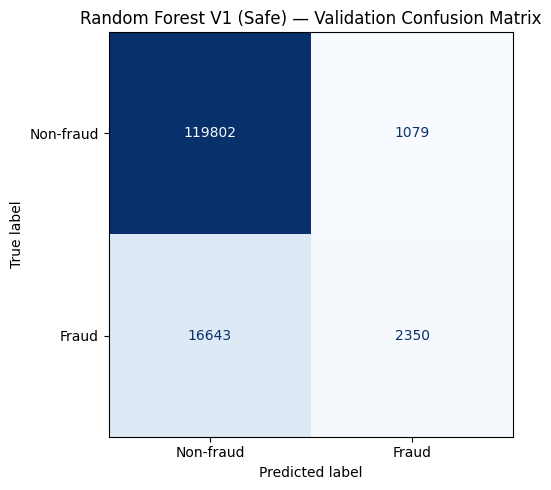

True Negatives: 119802
False Positives: 1079
False Negatives: 16643
True Positives: 2350


In [18]:
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay
)

cm_safe = confusion_matrix(
    y_val,
    y_val_pred_safe,
    labels=[0, 1]
)

tn_safe, fp_safe, fn_safe, tp_safe = cm_safe.ravel()

fig, ax = plt.subplots(figsize=(6, 5))

ConfusionMatrixDisplay(
    confusion_matrix=cm_safe,
    display_labels=["Non-fraud", "Fraud"]
).plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)

ax.set_title(
    "Random Forest V1 (Safe) — Validation Confusion Matrix"
)

plt.tight_layout()
plt.show()

print("True Negatives:", tn_safe)
print("False Positives:", fp_safe)
print("False Negatives:", fn_safe)
print("True Positives:", tp_safe)

### Confusion Matrix Observations

At the fixed decision threshold of 0.5, the Random
Forest Safe model produces:

- True Negatives: 119,802
- False Positives: 1,079
- False Negatives: 16,643
- True Positives: 2,350

The model correctly identifies 2,350 fraudulent orders
out of 18,993 actual fraud cases.

Compared with the Logistic Regression Safe model:

- 1,341 additional fraudulent orders are correctly detected.
- 772 additional legitimate orders are incorrectly flagged.
- False negatives decrease from 17,984 to 16,643.
- The number of flagged orders increases from 1,316
  to 3,429.

**Business Implications:**

Random Forest provides better fraud detection coverage,
but the improvement comes at the cost of additional
false positives and lower precision.

Additional false positives may increase unnecessary
investigations and negatively affect legitimate customers.

Furthermore, approximately 87.63% of actual fraudulent
orders remain undetected at the current decision threshold.

Therefore, although Random Forest demonstrates stronger
fraud ranking capability than Logistic Regression,
its current classification performance requires
further assessment against the stakeholder's requirement
of high precision with reasonable recall.

## 10. Version 2 — Random Forest (Full Dataset)

### 10.1 Training Data Preparation

Version 2 uses the Full dataset containing 41 prediction
features, including the 10 additional customer snapshot
features excluded from the Safe dataset.

The same chronological split, target labels and model
hyperparameters used in Version 1 are retained.

This controlled experimental design allows the potential
impact of the additional customer snapshot features
on Random Forest performance to be investigated.

The Full version is retained for exploratory analysis
because the availability of these additional features
at prediction time remains uncertain.

In [19]:
X_train_full = X_full.loc[train_mask]
X_val_full = X_full.loc[val_mask]
X_test_full = X_full.loc[test_mask]

# Verify consistent record alignment
assert X_train_full.index.equals(X_train_safe.index)
assert X_val_full.index.equals(X_val_safe.index)
assert X_test_full.index.equals(X_test_safe.index)

full_split_summary = pd.DataFrame({
    "Split": ["Train", "Validation", "Test"],
    "Records": [
        len(X_train_full),
        len(X_val_full),
        len(X_test_full)
    ],
    "Features": [
        X_train_full.shape[1],
        X_val_full.shape[1],
        X_test_full.shape[1]
    ],
    "Fraud Cases": [
        y_train.sum(),
        y_val.sum(),
        y_test.sum()
    ]
})

display(full_split_summary)

,Split,Records,Features,Fraud Cases
0,Train,665876,41,67594
1,Validation,139874,41,18993
2,Test,144122,41,17835


### 10.2 Model Training

A second Random Forest classifier is fitted using
the Full training dataset.

The same hyperparameter configuration used in Version 1
is retained to isolate the impact of the additional
customer snapshot features.

Training duration, tree depth, leaf nodes and total
tree nodes are recorded to compare computational
efficiency and model complexity between both versions.

Only the training dataset is used to fit the model.

In [20]:
# Create the Full Random Forest model
model_full = build_random_forest()

# Verify identical hyperparameter configuration
assert model_safe.get_params() == model_full.get_params()

# Record training time
start_time = time.perf_counter()

model_full.fit(
    X_train_full,
    y_train
)

training_time_full = (
    time.perf_counter() - start_time
)

# Retrieve individual tree information
tree_depths_full = [
    tree.get_depth()
    for tree in model_full.estimators_
]

tree_leaves_full = [
    tree.get_n_leaves()
    for tree in model_full.estimators_
]

tree_nodes_full = [
    tree.tree_.node_count
    for tree in model_full.estimators_
]

# Summarise model complexity
mean_depth_full = float(np.mean(tree_depths_full))
max_depth_full = int(np.max(tree_depths_full))
mean_leaves_full = float(np.mean(tree_leaves_full))
total_nodes_full = int(np.sum(tree_nodes_full))

print("Model: Random Forest")
print("Version: V2 - Full Dataset")
print("Training records:", len(X_train_full))
print("Number of features:", X_train_full.shape[1])
print(f"Training time: {training_time_full:.4f} seconds")
print("Number of trees:", len(model_full.estimators_))
print(f"Mean tree depth: {mean_depth_full:.2f}")
print("Maximum tree depth:", max_depth_full)
print(f"Mean leaf nodes: {mean_leaves_full:.2f}")
print("Total tree nodes:", total_nodes_full)

# Verify model configuration
assert len(model_full.estimators_) == MODEL_PARAMS["n_estimators"]
assert max_depth_full <= MODEL_PARAMS["max_depth"]
assert np.array_equal(model_full.classes_, [0, 1])

print("Model configuration check: Passed")

Model: Random Forest
Version: V2 - Full Dataset
Training records: 665876
Number of features: 41
Training time: 15.7375 seconds
Number of trees: 50
Mean tree depth: 15.00
Maximum tree depth: 15
Mean leaf nodes: 1618.80
Total tree nodes: 161830
Model configuration check: Passed


### Training Observations

- The Random Forest Full model was successfully trained
  on 665,876 orders using 41 prediction features.
- Model training took approximately 15.74 seconds,
  compared with 11.02 seconds for the Safe model.
- All 50 decision trees were successfully constructed.
- The mean and maximum tree depths remained at 15.
- The average number of leaf nodes increased from
  1,096.24 to 1,618.80 per tree.
- The total number of tree nodes increased from
  109,574 to 161,830.
- All model configuration checks passed.

Despite using the same hyperparameters, the Full model
developed a more complex tree structure.

The additional customer snapshot features may provide
more splitting opportunities, resulting in a larger
number of leaf nodes and increased training time.

However, greater model complexity does not necessarily
indicate better generalisation or predictive performance.

The complete automated retraining pipeline execution
time will be evaluated separately under PBI 5.

### 10.3 Validation Predictions

The trained Full Random Forest model generates fraud
probabilities for the training and validation datasets.

The same fixed decision threshold of 0.5 used in
Version 1 is retained to support controlled comparison.

The number of flagged orders and the distribution
of predicted fraud probabilities are examined before
evaluating classification and ranking performance.

The test dataset remains reserved for final evaluation.

In [21]:
# Generate fraud probabilities
y_train_prob_full = model_full.predict_proba(
    X_train_full
)[:, 1]

y_val_prob_full = model_full.predict_proba(
    X_val_full
)[:, 1]

# Convert probabilities into class predictions
y_val_pred_full = (
    y_val_prob_full >= THRESHOLD
).astype(int)

prediction_summary_full = pd.DataFrame({
    "Actual": y_val.to_numpy(),
    "Fraud Probability": y_val_prob_full,
    "Predicted": y_val_pred_full
})

# Display aggregate probability statistics
display(
    prediction_summary_full[
        "Fraud Probability"
    ].describe().to_frame()
)

print("Validation records:", len(y_val))
print("Actual fraud cases:", y_val.sum())
print("Predicted fraud cases:", y_val_pred_full.sum())
print("Decision threshold:", THRESHOLD)

,Fraud Probability
count,139874.000000
mean,0.105673
std,0.163946
min,0.005349
25%,0.014859
50%,0.029853
75%,0.095332
max,0.881789


Validation records: 139874
Actual fraud cases: 18993
Predicted fraud cases: 8334
Decision threshold: 0.5


**Observations:**

- Fraud probabilities were generated for all 139,874
  validation records.
- The mean predicted fraud probability is approximately
  0.1057, compared with 0.1039 for the Safe model.
- The standard deviation increased from approximately
  0.1196 to 0.1639, indicating greater variation in
  predicted fraud probabilities.
- The predicted probabilities range from approximately
  0.0053 to 0.8818.
- At the fixed decision threshold of 0.5, the Full
  model flags 8,334 orders as potentially fraudulent.
- The Safe model flags 3,429 orders at the same
  decision threshold.
- The Full model therefore flags 4,905 additional orders.

The additional customer snapshot features appear to
influence the distribution of predicted fraud probabilities
and increase the number of positive classifications.

However, the increase in flagged orders does not
necessarily indicate improved fraud detection, as
additional predictions may include false positives.

Further evaluation is required to determine whether
the additional features improve the precision-recall
trade-off.

### 10.4 Evaluation and MLflow Experiment Logging

The Full Random Forest model is logged using the
team's shared MLflow logging utilities.

The same logging configuration used in Version 1
is retained to ensure consistent experiment tracking.

The following information is recorded:

- Model hyperparameters and training configuration.
- Training duration and tree complexity information.
- Training and validation evaluation metrics.
- The trained Random Forest classifier and model signature.
- Confusion matrix and precision-recall curve.
- Prediction feature metadata.

The Full model is retained for exploratory comparison
because the point-in-time availability of the additional
customer snapshot features remains uncertain.

The test dataset remains reserved for final evaluation.

In [22]:
with start_model_run(
    member="abby",
    algorithm="random_forest",
    dataset_version="full",
    model_version="v2"
) as run:

    run_id_full = run.info.run_id

    # 1. Record model configuration
    log_model_parameters(
        model_params=MODEL_PARAMS,
        threshold=THRESHOLD,
        feature_count=X_train_full.shape[1]
    )

    mlflow.log_params({
        "scaler": "None",
        "training_records": len(X_train_full),
        "validation_records": len(X_val_full)
    })

    # 2. Record computational performance
    mlflow.log_metrics({
        "training_time_seconds": training_time_full,
        "mean_tree_depth": mean_depth_full,
        "max_tree_depth": max_depth_full,
        "mean_tree_leaves": mean_leaves_full,
        "total_tree_nodes": total_nodes_full
    })

    # 3. Record training metrics
    train_metrics_full = log_classification_metrics(
        y_true=y_train,
        y_prob=y_train_prob_full,
        threshold=THRESHOLD,
        split="train"
    )

    # 4. Record validation metrics
    val_metrics_full = log_classification_metrics(
        y_true=y_val,
        y_prob=y_val_prob_full,
        threshold=THRESHOLD,
        split="val"
    )

    # 5. Save trained Random Forest model
    model_info_full = log_trained_model(
        model=model_full,
        X_sample=X_train_full.head(5),
        model_name="random_forest_full",
        skops_trusted_types=[
            "sklearn.tree._tree.Tree"
        ]
    )

    # 6. Save evaluation artifacts
    log_evaluation_artifacts(
        y_true=y_val,
        y_prob=y_val_prob_full,
        feature_names=X_train_full.columns,
        threshold=THRESHOLD,
        split="val"
    )

print("MLflow logging completed.")
print("Run ID:", run_id_full)
print("Model URI:", model_info_full.model_uri)

c:\Users\User\OneDrive - Singapore Polytechnic\Desktop\MLOps_CA1_group5\.venv\Lib\site-packages\mlflow\types\utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(


🏃 View run abby_random_forest_full_v2 at: http://127.0.0.1:5004/#/experiments/1/runs/2f540eb6b80a4bb5b276a59ca3ced542
🧪 View experiment at: http://127.0.0.1:5004/#/experiments/1
MLflow logging completed.
Run ID: 2f540eb6b80a4bb5b276a59ca3ced542
Model URI: models:/m-78218eda28be443099e6758beaf009bb


### 10.5 Training and Validation Performance

Compare the training and validation performance of
the Full Random Forest model to investigate potential
overfitting or underfitting.

The same evaluation metrics used for the Safe model
are retained to support consistent comparison.

Precision remains the primary business consideration,
while recall is examined to determine whether the model
provides improved fraud detection coverage.

Average Precision and ROC-AUC are also considered
to assess ranking performance independently of the
fixed classification threshold.

In [23]:
metric_names = [
    "accuracy",
    "precision",
    "recall",
    "f1",
    "pr_auc",
    "roc_auc"
]

full_metrics_summary = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score",
        "PR-AUC (Average Precision)",
        "ROC-AUC"
    ],
    "Train": [
        train_metrics_full[f"train_{metric}"]
        for metric in metric_names
    ],
    "Validation": [
        val_metrics_full[f"val_{metric}"]
        for metric in metric_names
    ]
})

display(full_metrics_summary.round(4))

,Metric,Train,Validation
0,Accuracy,0.9238,0.8789
1,Precision,0.7279,0.6231
2,Recall,0.3975,0.2734
3,F1-score,0.5142,0.3801
4,PR-AUC (Average Precision),0.6520,0.5636
5,ROC-AUC,0.9296,0.8962


### Performance Observations

- The Random Forest Full model achieves a validation
  accuracy of 87.89%, precision of 62.31% and recall
  of 27.34%.

- The validation F1-score is 0.3801, while Average
  Precision and ROC-AUC reach 0.5636 and 0.8962,
  respectively.

- All validation metrics are lower than their
  corresponding training metrics, indicating a
  generalisation gap.

- Training recall decreases from 39.75% to 27.34%
  on the validation dataset.

- Average Precision decreases from 0.6520 during
  training to 0.5636 during validation.

- The Full model exhibits a larger generalisation
  gap than the Safe model across several metrics,
  suggesting a greater potential risk of overfitting.

- However, differences in data distribution across
  chronological periods may also contribute to
  the observed performance gap.

Compared with the Safe model, the Full model achieves
higher validation recall, F1-score, Average Precision
and ROC-AUC, but lower precision.

Although the additional customer snapshot features
appear to improve fraud detection and ranking
performance, their point-in-time availability remains
uncertain.

Therefore, the improved performance cannot be interpreted
as sufficient evidence of production suitability.

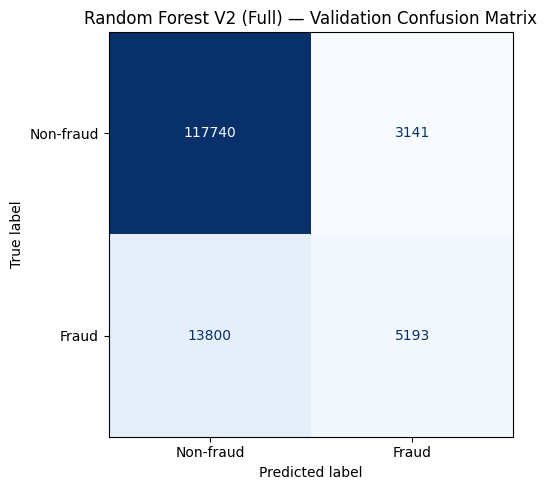

True Negatives: 117740
False Positives: 3141
False Negatives: 13800
True Positives: 5193


In [24]:
cm_full = confusion_matrix(
    y_val,
    y_val_pred_full,
    labels=[0, 1]
)

tn_full, fp_full, fn_full, tp_full = cm_full.ravel()

fig, ax = plt.subplots(figsize=(6, 5))

ConfusionMatrixDisplay(
    confusion_matrix=cm_full,
    display_labels=["Non-fraud", "Fraud"]
).plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)

ax.set_title(
    "Random Forest V2 (Full) — Validation Confusion Matrix"
)

plt.tight_layout()
plt.show()

print("True Negatives:", tn_full)
print("False Positives:", fp_full)
print("False Negatives:", fn_full)
print("True Positives:", tp_full)

### Confusion Matrix Observations

At the fixed decision threshold of 0.5, the Random
Forest Full model produces:

- True Negatives: 117,740
- False Positives: 3,141
- False Negatives: 13,800
- True Positives: 5,193

The model correctly identifies 5,193 fraudulent orders
out of 18,993 actual fraud cases.

Compared with the Random Forest Safe model:

- The number of correctly detected fraudulent orders
  increases by 2,843.
- The number of incorrectly flagged legitimate orders
  increases by 2,062.
- False negatives decrease from 16,643 to 13,800.
- Flagged orders increase from 3,429 to 8,334.
- Fraud recall increases from approximately 12.37%
  to 27.34%.

**Business Implications:**

The Full model provides greater fraud detection coverage,
but also generates more false positives.

The additional false positives may increase unnecessary
investigations and negatively affect legitimate customers.

Despite the improvement in detection coverage,
approximately 72.66% of actual fraudulent orders remain
undetected at the current decision threshold.

Furthermore, the point-in-time availability of the
additional customer snapshot features remains uncertain.

Therefore, the Full model is retained for exploratory
comparison rather than recommended for production
deployment.

## 11. Safe vs Full Model Comparison

Both Random Forest versions are compared using
the same validation records, model hyperparameters
and decision threshold.

The comparison evaluates predictive performance,
business impact, computational efficiency, model
complexity and potential temporal data leakage.

Model selection is guided by the stakeholder's
requirement to prioritise high precision while
maintaining reasonable recall.

### 11.1 Overall Performance Comparison

Compare the validation performance of both Random
Forest versions using the six agreed evaluation
metrics.

The absolute differences between the Safe and Full
models are calculated to assess the impact of the
additional customer snapshot features.

The decision threshold remains fixed at 0.5 to
ensure consistent baseline comparison.

In [25]:
comparison_rf = pd.DataFrame({
    "Metric": safe_metrics_summary["Metric"],
    "V1 - Safe": [
        val_metrics_safe[f"val_{metric}"]
        for metric in metric_names
    ],
    "V2 - Full": [
        val_metrics_full[f"val_{metric}"]
        for metric in metric_names
    ]
})

comparison_rf["Difference (Full - Safe)"] = (
    comparison_rf["V2 - Full"] -
    comparison_rf["V1 - Safe"]
)

display(comparison_rf.round(4))

,Metric,V1 - Safe,V2 - Full,Difference (Full - Safe)
0,Accuracy,0.8733,0.8789,0.0056
1,Precision,0.6853,0.6231,-0.0622
2,Recall,0.1237,0.2734,0.1497
3,F1-score,0.2096,0.3801,0.1704
4,PR-AUC (Average Precision),0.5289,0.5636,0.0347
5,ROC-AUC,0.8554,0.8962,0.0408


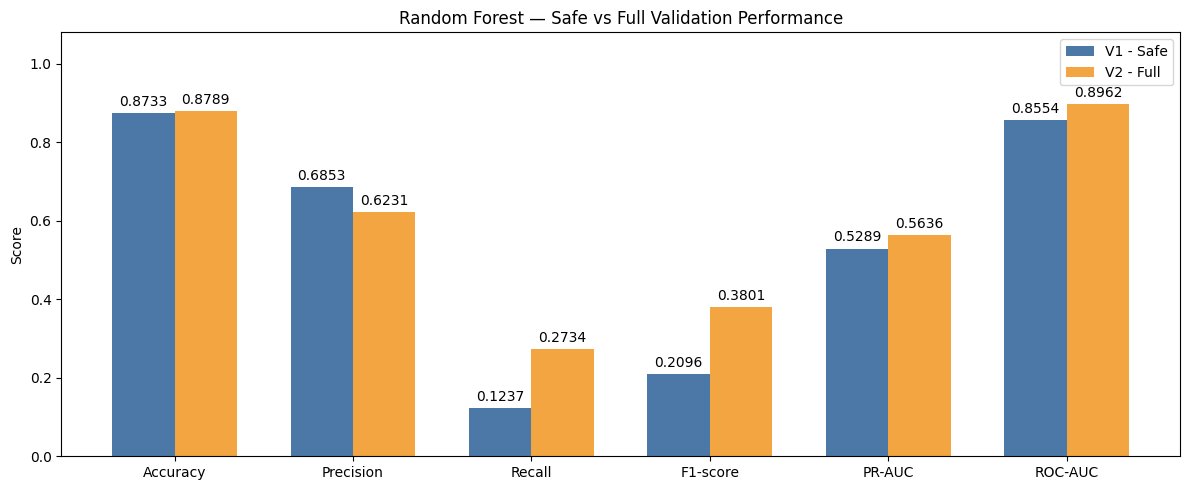

In [26]:
fig, ax = plt.subplots(figsize=(12, 5))

positions = np.arange(len(comparison_rf))
width = 0.35

bars_safe = ax.bar(
    positions - width / 2,
    comparison_rf["V1 - Safe"],
    width,
    label="V1 - Safe",
    color="#4C78A8"
)

bars_full = ax.bar(
    positions + width / 2,
    comparison_rf["V2 - Full"],
    width,
    label="V2 - Full",
    color="#F2A541"
)

ax.bar_label(bars_safe, fmt="%.4f", padding=3)
ax.bar_label(bars_full, fmt="%.4f", padding=3)

ax.set_xticks(positions)
ax.set_xticklabels([
    "Accuracy",
    "Precision",
    "Recall",
    "F1-score",
    "PR-AUC",
    "ROC-AUC"
])

ax.set_title(
    "Random Forest — Safe vs Full Validation Performance"
)

ax.set_ylabel("Score")
ax.set_ylim(0, 1.08)
ax.legend()

plt.tight_layout()
plt.show()

**Observations:**

- The Full model outperforms the Safe model in
  five of the six validation metrics.

- Recall increases from 0.1237 to 0.2734,
  representing a substantial improvement in
  fraud detection coverage.

- F1-score increases from 0.2096 to 0.3801,
  indicating a stronger combined precision-recall
  performance.

- Average Precision improves from 0.5289 to 0.5636,
  while ROC-AUC improves from 0.8554 to 0.8962.

- However, precision decreases from 0.6853 to 0.6231.

- The improvement in accuracy is relatively small
  compared with the improvement in recall.

Although the Full model demonstrates stronger ranking
performance and detection coverage, the Safe model
maintains higher precision at the fixed threshold.

This trade-off is important because precision is
the stakeholder's primary business priority.

The performance improvements of the Full model must
also be interpreted cautiously because of the uncertain
point-in-time availability of its additional features.

### 11.2 Computational Efficiency Comparison

Compare feature counts, model fitting times, tree
depths, leaf counts and total tree nodes to assess
the computational cost of including additional features.

The recorded training duration measures model fitting
only, rather than the complete ETL or automated
retraining pipeline.

Both models use the same configured number of trees
and maximum tree depth.

In [27]:
efficiency_comparison = pd.DataFrame({
    "Measurement": [
        "Prediction Features",
        "Training Time (seconds)",
        "Number of Trees",
        "Mean Tree Depth",
        "Maximum Tree Depth",
        "Mean Leaf Nodes",
        "Total Tree Nodes"
    ],
    "V1 - Safe": [
        X_train_safe.shape[1],
        training_time_safe,
        len(model_safe.estimators_),
        mean_depth_safe,
        max_depth_safe,
        mean_leaves_safe,
        total_nodes_safe
    ],
    "V2 - Full": [
        X_train_full.shape[1],
        training_time_full,
        len(model_full.estimators_),
        mean_depth_full,
        max_depth_full,
        mean_leaves_full,
        total_nodes_full
    ]
})

efficiency_comparison["Change (%)"] = (
    (
        efficiency_comparison["V2 - Full"] -
        efficiency_comparison["V1 - Safe"]
    ) /
    efficiency_comparison["V1 - Safe"] * 100
)

display(efficiency_comparison.round(4))

,Measurement,V1 - Safe,V2 - Full,Change (%)
0,Prediction Features,31.0000,41.0000,32.2581
1,Training Time (seconds),11.0171,15.7375,42.8459
2,Number of Trees,50.0000,50.0000,0.0000
3,Mean Tree Depth,15.0000,15.0000,0.0000
4,Maximum Tree Depth,15.0000,15.0000,0.0000
5,Mean Leaf Nodes,1096.2400,1618.8000,47.6684
6,Total Tree Nodes,109574.0000,161830.0000,47.6901


**Observations:**

- The Full model uses 10 additional prediction features
  compared with the Safe model.
- The Full model takes approximately 15.74 seconds
  to train, compared with 11.02 seconds for the Safe
  model, an increase of 42.85% in this execution.
- Both versions contain 50 decision trees and reach
  the configured maximum depth of 15.
- The average number of leaf nodes increases from
  1,096.24 to 1,618.80.
- The total number of tree nodes increases from
  109,574 to 161,830, representing an increase of
  approximately 47.69%.
- Despite identical configured hyperparameters, the
  Full model develops a more complex tree structure.
- The additional features provide more potential
  splitting opportunities.
- With max_features set to sqrt, the effective number
  of candidate features considered at each split also
  changes with the feature set size.

The Safe model provides a more compact tree structure,
which may benefit model storage and computational
efficiency.

The recorded durations represent model fitting only
and may vary with system load. The three-minute ETL
requirement and the complete automated retraining
workflow must be evaluated separately under PBI 5.

### 11.3 ROC and Precision-Recall Curve Comparison

Compare the ranking performance of both Random Forest
versions across different decision thresholds.

ROC-AUC measures the model's ability to discriminate
between fraudulent and non-fraudulent orders.

The precision-recall curve and Average Precision
are particularly relevant because the fraud dataset
is imbalanced and the stakeholder prioritises high
precision while maintaining reasonable recall.

The random precision-recall baseline corresponds
to the fraud prevalence in the validation dataset.

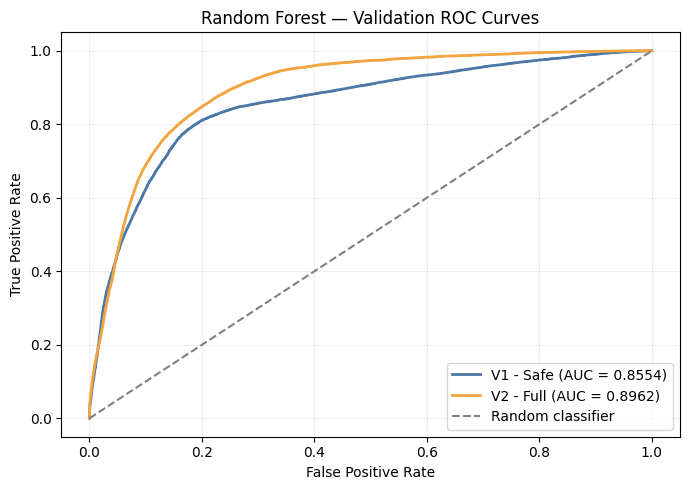

In [28]:
from sklearn.metrics import (
    roc_curve,
    precision_recall_curve
)

# Calculate ROC curves
fpr_safe, tpr_safe, _ = roc_curve(
    y_val,
    y_val_prob_safe
)

fpr_full, tpr_full, _ = roc_curve(
    y_val,
    y_val_prob_full
)

fig, ax = plt.subplots(figsize=(7, 5))

ax.plot(
    fpr_safe,
    tpr_safe,
    label=(
        f"V1 - Safe "
        f"(AUC = {val_metrics_safe['val_roc_auc']:.4f})"
    ),
    color="#4C78A8",
    linewidth=2
)

ax.plot(
    fpr_full,
    tpr_full,
    label=(
        f"V2 - Full "
        f"(AUC = {val_metrics_full['val_roc_auc']:.4f})"
    ),
    color="#F2A541",
    linewidth=2
)

ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="grey",
    label="Random classifier"
)

ax.set_title("Random Forest — Validation ROC Curves")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.legend(loc="lower right")
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

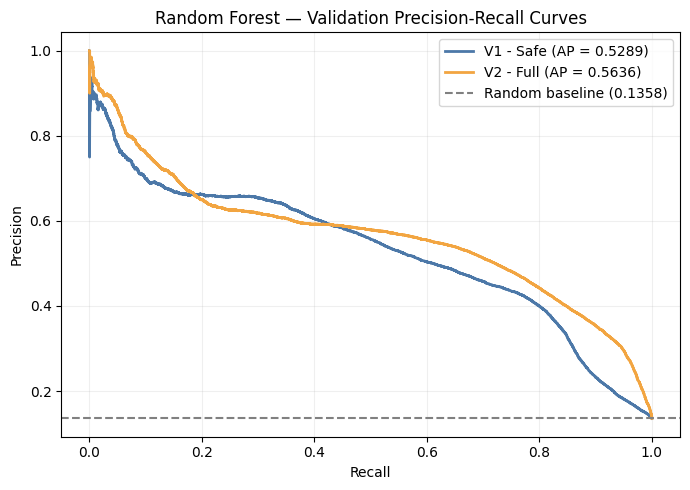

In [29]:
# Calculate precision-recall curves
precision_safe, recall_safe, _ = precision_recall_curve(
    y_val,
    y_val_prob_safe
)

precision_full, recall_full, _ = precision_recall_curve(
    y_val,
    y_val_prob_full
)

# Random classifier baseline
fraud_baseline = y_val.mean()

fig, ax = plt.subplots(figsize=(7, 5))

ax.plot(
    recall_safe,
    precision_safe,
    label=(
        f"V1 - Safe "
        f"(AP = {val_metrics_safe['val_pr_auc']:.4f})"
    ),
    color="#4C78A8",
    linewidth=2
)

ax.plot(
    recall_full,
    precision_full,
    label=(
        f"V2 - Full "
        f"(AP = {val_metrics_full['val_pr_auc']:.4f})"
    ),
    color="#F2A541",
    linewidth=2
)

ax.axhline(
    fraud_baseline,
    linestyle="--",
    color="grey",
    label=f"Random baseline ({fraud_baseline:.4f})"
)

ax.set_title(
    "Random Forest — Validation Precision-Recall Curves"
)

ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

**Observations:**

- Both Random Forest versions substantially outperform
  the random classifier baseline.
- The Full model achieves a higher ROC-AUC of 0.8962,
  compared with 0.8554 for the Safe model.
- The Full model demonstrates stronger overall
  discrimination across most false positive rates.
- Average Precision increases from 0.5289 for the
  Safe model to 0.5636 for the Full model.
- Both Average Precision scores are substantially
  higher than the random precision-recall baseline
  of approximately 0.1358.
- The precision-recall curves intersect, indicating
  that neither model consistently dominates across
  all operating points.
- The Safe model achieves higher precision across
  part of the intermediate recall region.

**Business Implications:**

Although the Full model provides stronger overall
ranking performance, model selection should not
be based solely on ROC-AUC or Average Precision.

The stakeholder prioritises high precision while
maintaining reasonable recall. Therefore, the
performance of both models at different decision
thresholds should be investigated.

Furthermore, the Full model remains exploratory
because of the uncertain point-in-time availability
of its additional customer snapshot features.

## 12. Potential Model Improvements

### 12.1 Decision Threshold Sensitivity Analysis

Both Random Forest versions demonstrated limited
recall at the default decision threshold of 0.5.

To investigate potential improvements, different
classification thresholds are evaluated using the
existing validation probabilities.

This analysis examines whether fraud detection coverage
can be increased while maintaining sufficiently high
precision and limiting unnecessary investigations.

The same candidate thresholds used in the Logistic
Regression experiments are retained for consistency.

No additional model is trained. The original model
configurations and logged experiment results remain
unchanged.

The results are exploratory and are not used to modify
the final test evaluation threshold.

In [31]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

threshold_results = []

thresholds = [
    0.05, 0.10, 0.15, 0.20, 0.25,
    0.30, 0.35, 0.40, 0.45, 0.50,
    0.55, 0.60, 0.65, 0.70
]

for version, probabilities in [
    ("V1 - Safe", y_val_prob_safe),
    ("V2 - Full", y_val_prob_full)
]:

    for threshold in thresholds:

        predictions = (
            probabilities >= threshold
        ).astype(int)

        tn_t, fp_t, fn_t, tp_t = confusion_matrix(
            y_val,
            predictions,
            labels=[0, 1]
        ).ravel()

        threshold_results.append({
            "Version": version,
            "Threshold": threshold,
            "Precision": precision_score(
                y_val,
                predictions,
                zero_division=0
            ),
            "Recall": recall_score(
                y_val,
                predictions,
                zero_division=0
            ),
            "F1-score": f1_score(
                y_val,
                predictions,
                zero_division=0
            ),
            "True Positives": tp_t,
            "False Positives": fp_t,
            "False Negatives": fn_t,
            "Flagged Orders": tp_t + fp_t
        })

threshold_df = pd.DataFrame(threshold_results)

display(
    threshold_df[
        threshold_df["Version"] == "V1 - Safe"
    ].round(4)
)

display(
    threshold_df[
        threshold_df["Version"] == "V2 - Full"
    ].round(4)
)

,Version,Threshold,Precision,Recall,F1-score,True Positives,False Positives,False Negatives,Flagged Orders
0,V1 - Safe,0.05,0.2140,0.9174,0.3471,17425,63999,1568,81424
1,V1 - Safe,0.10,0.3881,0.8108,0.5250,15399,24276,3594,39675
2,V1 - Safe,0.15,0.4456,0.7268,0.5525,13804,17173,5189,30977
3,V1 - Safe,0.20,0.5184,0.5698,0.5429,10822,10053,8171,20875
4,V1 - Safe,0.25,0.6018,0.4066,0.4853,7722,5109,11271,12831
5,V1 - Safe,0.30,0.6434,0.3316,0.4377,6299,3491,12694,9790
6,V1 - Safe,0.35,0.6574,0.2799,0.3927,5317,2771,13676,8088
7,V1 - Safe,0.40,0.6584,0.2236,0.3338,4246,2203,14747,6449
8,V1 - Safe,0.45,0.6635,0.1665,0.2662,3163,1604,15830,4767
9,V1 - Safe,0.50,0.6853,0.1237,0.2096,2350,1079,16643,3429


,Version,Threshold,Precision,Recall,F1-score,True Positives,False Positives,False Negatives,Flagged Orders
14,V2 - Full,0.05,0.3158,0.9358,0.4722,17774,38516,1219,56290
15,V2 - Full,0.10,0.4446,0.7967,0.5707,15132,18905,3861,34037
16,V2 - Full,0.15,0.4994,0.7225,0.5906,13723,13755,5270,27478
17,V2 - Full,0.20,0.5331,0.6620,0.5906,12574,11014,6419,23588
18,V2 - Full,0.25,0.5564,0.5968,0.5759,11335,9038,7658,20373
19,V2 - Full,0.30,0.5736,0.5307,0.5513,10079,7492,8914,17571
20,V2 - Full,0.35,0.5855,0.4622,0.5166,8778,6214,10215,14992
21,V2 - Full,0.40,0.5924,0.3975,0.4758,7550,5195,11443,12745
22,V2 - Full,0.45,0.6077,0.3377,0.4341,6414,4141,12579,10555
23,V2 - Full,0.50,0.6231,0.2734,0.3801,5193,3141,13800,8334


### 12.2 Threshold Sensitivity Visualization

Plot precision, recall and F1-score against the
candidate decision thresholds for each Random
Forest version.

The dashed vertical line marks the original
decision threshold of 0.5.

The visualisation helps identify potential operating
points that may better satisfy the stakeholder's
business requirements without changing the trained
models or their baseline configurations.

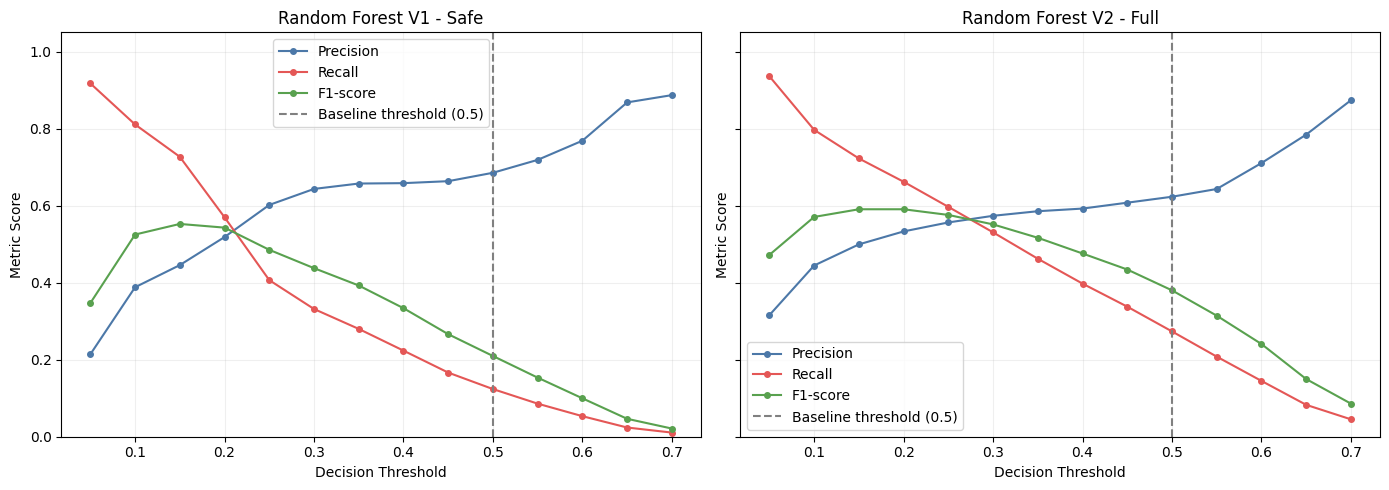

In [32]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 5),
    sharey=True
)

for ax, version in zip(
    axes,
    ["V1 - Safe", "V2 - Full"]
):

    version_results = threshold_df[
        threshold_df["Version"] == version
    ]

    for metric, color in [
        ("Precision", "#4C78A8"),
        ("Recall", "#E45756"),
        ("F1-score", "#59A14F")
    ]:
        ax.plot(
            version_results["Threshold"],
            version_results[metric],
            marker="o",
            markersize=4,
            label=metric,
            color=color
        )

    ax.axvline(
        THRESHOLD,
        linestyle="--",
        color="grey",
        label="Baseline threshold (0.5)"
    )

    ax.set_title(
        f"Random Forest {version}"
    )

    ax.set_xlabel("Decision Threshold")
    ax.set_ylabel("Metric Score")
    ax.set_ylim(0, 1.05)
    ax.legend()
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

### 12.3 Identify Potential Operating Points

Identify the threshold with the highest F1-score
for each model as an exploratory reference.

As the stakeholder prioritises precision, additional
operating points are examined using illustrative
minimum precision levels of 0.60, 0.70 and 0.80.

These precision levels are exploratory comparison
criteria rather than formal stakeholder requirements.

For each minimum precision level, identify the
candidate threshold that provides the highest recall
while satisfying the precision condition.

In [33]:
# Identify maximum F1 operating points
best_f1_thresholds = threshold_df.loc[
    threshold_df.groupby("Version")[
        "F1-score"
    ].idxmax()
]

print("Highest F1-score operating points:")
display(best_f1_thresholds.round(4))

# Investigate precision-prioritised operating points
precision_targets = [0.60, 0.70, 0.80]

operating_points = []

for version in ["V1 - Safe", "V2 - Full"]:

    version_results = threshold_df[
        threshold_df["Version"] == version
    ]

    for target in precision_targets:

        eligible = version_results[
            (version_results["Precision"] >= target) &
            (version_results["Flagged Orders"] > 0)
        ]

        if not eligible.empty:

            best = eligible.sort_values(
                ["Recall", "Precision"],
                ascending=False
            ).iloc[0]

            operating_points.append({
                "Version": version,
                "Minimum Precision": target,
                "Threshold": best["Threshold"],
                "Precision": best["Precision"],
                "Recall": best["Recall"],
                "F1-score": best["F1-score"],
                "True Positives": best["True Positives"],
                "False Positives": best["False Positives"],
                "Status": "Available"
            })

        else:

            operating_points.append({
                "Version": version,
                "Minimum Precision": target,
                "Status": "Not achieved"
            })

operating_points_df = pd.DataFrame(operating_points)

display(operating_points_df.round(4))

Highest F1-score operating points:


,Version,Threshold,Precision,Recall,F1-score,True Positives,False Positives,False Negatives,Flagged Orders
2,V1 - Safe,0.15,0.4456,0.7268,0.5525,13804,17173,5189,30977
16,V2 - Full,0.15,0.4994,0.7225,0.5906,13723,13755,5270,27478


,Version,Minimum Precision,Threshold,Precision,Recall,F1-score,True Positives,False Positives,Status
0,V1 - Safe,0.6,0.25,0.6018,0.4066,0.4853,7722,5109,Available
1,V1 - Safe,0.7,0.55,0.7188,0.0859,0.1534,1631,638,Available
2,V1 - Safe,0.8,0.65,0.8681,0.0239,0.0465,454,69,Available
3,V2 - Full,0.6,0.45,0.6077,0.3377,0.4341,6414,4141,Available
4,V2 - Full,0.7,0.60,0.7106,0.1449,0.2407,2752,1121,Available
5,V2 - Full,0.8,0.70,0.8737,0.0452,0.0859,858,124,Available


### Threshold Sensitivity Observations

**1. Effect of Decision Threshold**

- Lower decision thresholds generally increase recall
  and the number of correctly detected fraudulent orders.
- However, they also increase false positives and the
  number of orders requiring investigation.
- Higher thresholds generally improve precision but
  substantially reduce fraud detection coverage.
- Therefore, the default threshold of 0.5 is not
  necessarily the most suitable operating point for
  the stakeholder's business requirements.

**2. Maximum F1-score Analysis**

- Among the evaluated candidate thresholds, both
  models achieve their highest F1-score at 0.15.
- The Safe model achieves an F1-score of 0.5525,
  while the Full model achieves 0.5906.
- However, their corresponding precision values are
  only 0.4456 and 0.4994, respectively.
- More than half of the flagged orders are legitimate
  at these operating points.

Selecting a threshold solely by maximising F1-score
may therefore conflict with the stakeholder's
precision-focused business objective.

**3. Precision-prioritised Analysis**

At an illustrative minimum precision level of 60%:

- The Safe model achieves precision of 60.18%
  and recall of 40.66% at a threshold of 0.25.
- The Full model achieves precision of 60.77%
  and recall of 33.77% at a threshold of 0.45.

The Safe model achieves higher recall under this
precision condition among the evaluated thresholds,
despite having lower overall Average Precision.

At minimum precision levels of 70% and 80%, the
Full model achieves higher recall than the Safe model
among the evaluated candidate thresholds.

However, both models demonstrate limited fraud
detection coverage at these higher precision levels.

**4. Potential Improvement for the Safe Model**

Reducing the Safe model's threshold from 0.5 to 0.25:

- Increases recall from 12.37% to 40.66%.
- Increases F1-score from 0.2096 to 0.4853.
- Correctly detects 5,372 additional fraudulent orders.
- Reduces false negatives from 16,643 to 11,271.
- Reduces precision from 68.53% to 60.18%.
- Increases false positives from 1,079 to 5,109.

This demonstrates that threshold adjustment can
substantially improve fraud detection coverage without
retraining the classifier.

However, the additional false positives may increase
investigation workload and negatively affect
legitimate customers.

**5. Business Recommendation**

Threshold optimisation is a promising potential
improvement for the Random Forest Safe model.

The final operating threshold should be determined
with the stakeholder after considering acceptable
precision, minimum recall, investigation capacity
and the business costs of classification errors.

The illustrative precision targets are not formal
stakeholder requirements, and the analysis is limited
to the evaluated candidate thresholds.

The Full model remains exploratory due to the
uncertain point-in-time availability of its additional
customer snapshot features.

The original model configurations, MLflow experiment
results and decision threshold of 0.5 are retained
for the final test evaluation.

## 13. Model Interpretability

### 13.1 Random Forest Feature Importance Analysis

Random Forest provides impurity-based feature
importance scores that measure the relative
contribution of prediction features to reducing
impurity across the fitted decision trees.

As both models use the Gini criterion, feature
importance is based on weighted reductions in
Gini impurity.

The importance scores are normalised so that their
sum equals one for each fitted forest.

Higher importance scores indicate greater relative
contribution to the model's splitting decisions.

Unlike Logistic Regression coefficients, these
scores do not indicate whether a feature increases
or decreases predicted fraud probability.

This analysis uses the existing trained models
without retraining or modifying their configurations.

In [34]:
# Extract impurity-based feature importance
importance_safe = pd.DataFrame({
    "Feature": X_train_safe.columns,
    "Importance": model_safe.feature_importances_
})

importance_full = pd.DataFrame({
    "Feature": X_train_full.columns,
    "Importance": model_full.feature_importances_
})

# Identify feature groups
importance_safe["Feature Set"] = "Shared"

importance_full["Feature Set"] = np.where(
    importance_full["Feature"].isin(additional_features),
    "Full-only Snapshot",
    "Shared"
)

# Sort features by importance
importance_safe = (
    importance_safe
    .sort_values("Importance", ascending=False)
    .reset_index(drop=True)
)

importance_full = (
    importance_full
    .sort_values("Importance", ascending=False)
    .reset_index(drop=True)
)

# Assign feature ranks
importance_safe.insert(
    0, "Rank", np.arange(1, len(importance_safe) + 1)
)

importance_full.insert(
    0, "Rank", np.arange(1, len(importance_full) + 1)
)

# Verify importance scores
assert len(importance_safe) == X_train_safe.shape[1]
assert len(importance_full) == X_train_full.shape[1]

assert np.isclose(
    importance_safe["Importance"].sum(), 1.0
)

assert np.isclose(
    importance_full["Importance"].sum(), 1.0
)

print("V1 - Safe: Top 15 Influential Features")
display(importance_safe.head(15).round(4))

print("V2 - Full: Top 15 Influential Features")
display(importance_full.head(15).round(4))

print("Feature importance validation: Passed")

V1 - Safe: Top 15 Influential Features


,Rank,Feature,Importance,Feature Set
0,1,account_age_days,0.3318,Shared
1,2,log_order_value,0.1332,Shared
2,3,country_code_PK,0.1056,Shared
3,4,country_code_MY,0.0840,Shared
4,5,country_code_BD,0.0638,Shared
5,6,log_num_items_ordered,0.0621,Shared
6,7,value_per_item,0.0507,Shared
7,8,country_code_PH,0.0447,Shared
8,9,payment_method_payment_on_delivery,0.0271,Shared
9,10,country_code_TH,0.0197,Shared


V2 - Full: Top 15 Influential Features


,Rank,Feature,Importance,Feature Set
0,1,log_num_associated_customers,0.2667,Full-only Snapshot
1,2,account_age_days,0.1351,Shared
2,3,log_order_value,0.0718,Shared
3,4,log_total_payment_last_50days,0.0687,Full-only Snapshot
4,5,country_code_MY,0.0525,Shared
5,6,avg_payment_per_order,0.0506,Full-only Snapshot
6,7,country_code_PK,0.0506,Shared
7,8,log_num_orders_last_50days,0.0496,Full-only Snapshot
8,9,log_num_items_ordered,0.0330,Shared
9,10,country_code_BD,0.0313,Shared


Feature importance validation: Passed


**Observations:**

**V1 - Safe Model**

- Account age is the most influential predictor,
  accounting for approximately 33.18% of the total
  impurity-based feature importance.
- Log-transformed order value ranks second, with
  an importance score of 0.1332.
- Country-specific indicators, order quantity and
  value per item are also influential predictors.
- The five highest-ranked features account for
  approximately 71.84% of total feature importance.

**V2 - Full Model**

- The log-transformed number of associated customers
  becomes the most influential predictor, accounting
  for approximately 26.67% of total feature importance.
- Account age and log-transformed order value rank
  second and third, respectively.
- Customer payment history and recent order activity
  also appear among the highest-ranked predictors.

The results indicate that the two models exhibit
different feature importance distributions despite
using identical configured hyperparameters.

These importance scores describe the fitted models'
splitting behaviour rather than causal relationships
or the direction of individual feature effects.

### 13.2 Comparison of Influential Predictors

The 15 features with the highest impurity-based
importance scores are visualised for each Random
Forest version.

A common horizontal axis is used to support
comparison of relative importance scores.

Shared prediction features and Full-only customer
snapshot features are distinguished using different
colours.

This analysis examines how the additional customer
snapshot features influence the model's relative
feature importance distribution.

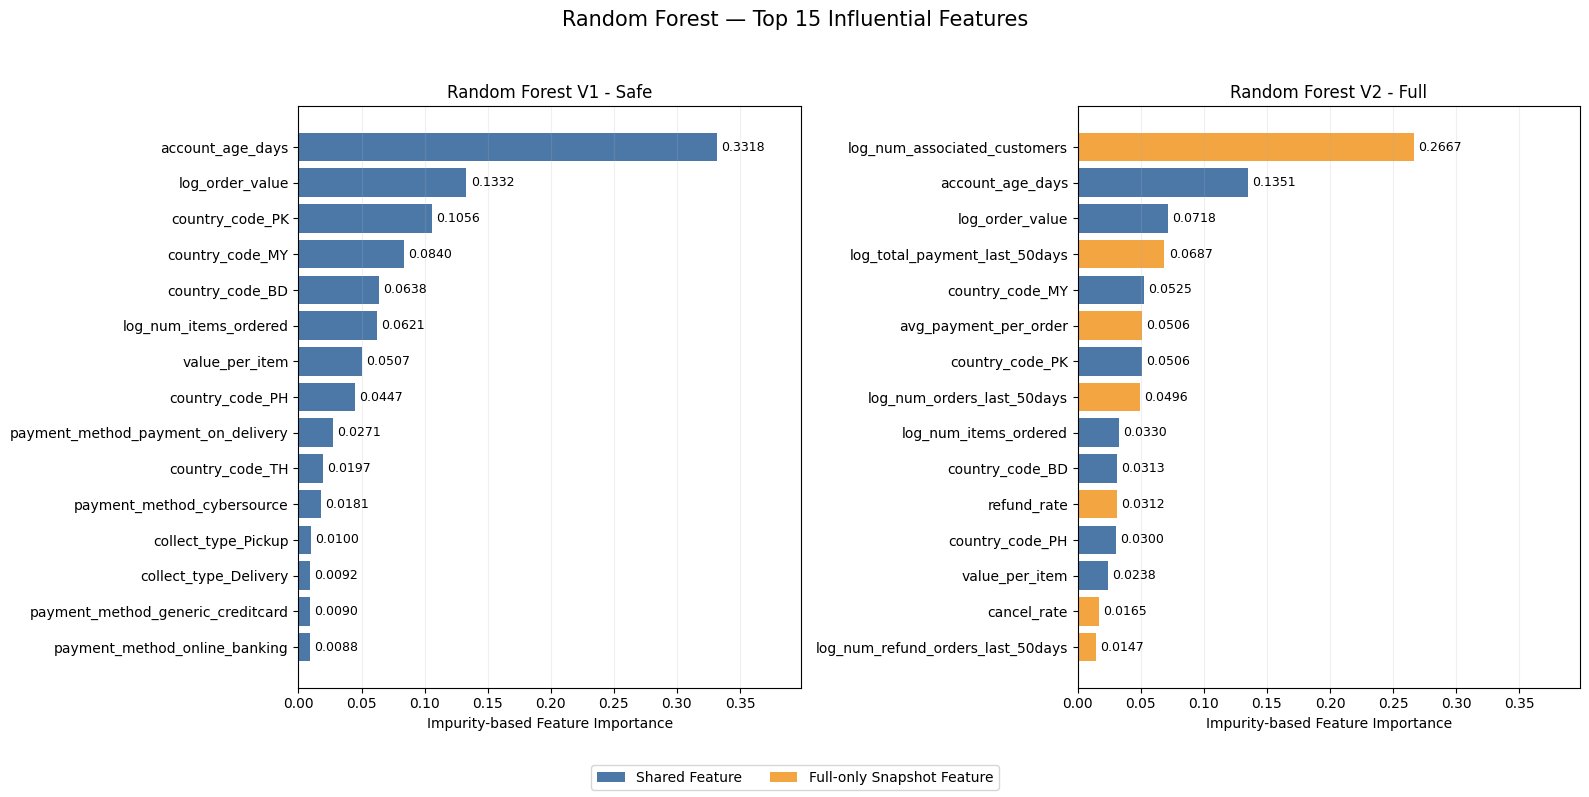

In [35]:
from matplotlib.patches import Patch

fig, axes = plt.subplots(
    1, 2,
    figsize=(16, 8),
    sharex=True
)

# Use a common horizontal axis
max_importance = max(
    importance_safe["Importance"].max(),
    importance_full["Importance"].max()
)

for ax, importance_df, version in [
    (axes[0], importance_safe, "V1 - Safe"),
    (axes[1], importance_full, "V2 - Full")
]:

    top_features = (
        importance_df.head(15)
        .sort_values("Importance", ascending=True)
    )

    colors = [
        "#F2A541" if group == "Full-only Snapshot"
        else "#4C78A8"
        for group in top_features["Feature Set"]
    ]

    bars = ax.barh(
        top_features["Feature"],
        top_features["Importance"],
        color=colors
    )

    ax.bar_label(
        bars,
        fmt="%.4f",
        padding=3,
        fontsize=9
    )

    ax.set_title(f"Random Forest {version}")
    ax.set_xlabel("Impurity-based Feature Importance")
    ax.set_xlim(0, max_importance * 1.20)
    ax.grid(axis="x", alpha=0.2)

legend_elements = [
    Patch(
        facecolor="#4C78A8",
        label="Shared Feature"
    ),
    Patch(
        facecolor="#F2A541",
        label="Full-only Snapshot Feature"
    )
]

fig.legend(
    handles=legend_elements,
    loc="lower center",
    ncol=2
)

fig.suptitle(
    "Random Forest — Top 15 Influential Features",
    fontsize=15
)

plt.tight_layout(rect=[0, 0.06, 1, 0.95])
plt.show()

**Observations:**

- Account age and order value remain influential
  predictors in both Random Forest versions.
- Account age decreases in relative importance
  from 0.3318 in the Safe model to 0.1351
  in the Full model.
- Order value decreases in relative importance
  from 0.1332 to 0.0718.
- Several country-specific indicators also receive
  lower relative importance in the Full model.
- Seven of the 15 highest-ranked Full model features
  are additional customer snapshot features.

The introduction of customer snapshot features
changes the distribution of importance across
the fitted forest.

The Full model assigns substantial importance to
customer association, historical payments and
recent order activity.

However, importance scores are normalised separately
for each model. A reduction in relative importance
does not necessarily indicate a reduction in the
absolute predictive contribution of a feature.

### 13.3 Influence of Customer Snapshot Features

The Full model contains 10 additional customer
snapshot features that are excluded from the
Safe model.

Their individual importance scores, feature ranks
and combined importance are examined to assess
their relative contribution within the fitted forest.

The number of customer snapshot features appearing
among the top 15 influential predictors is also
investigated.

This analysis supports the investigation of potential
reliance on features whose point-in-time availability
remains uncertain.

High feature importance alone does not establish
that temporal data leakage has occurred.

In [36]:
# Extract the 10 Full-only snapshot features
snapshot_importance = importance_full.loc[
    importance_full["Feature Set"] == "Full-only Snapshot"
].copy()

assert len(snapshot_importance) == 10

display(snapshot_importance.round(4))

# Calculate combined importance
snapshot_total_importance = (
    snapshot_importance["Importance"].sum()
)

shared_total_importance = (
    importance_full.loc[
        importance_full["Feature Set"] == "Shared",
        "Importance"
    ].sum()
)

# Count snapshot features within the top 15
top15_snapshot_count = (
    importance_full.head(15)["Feature Set"]
    == "Full-only Snapshot"
).sum()

snapshot_summary = pd.DataFrame({
    "Measurement": [
        "Total Full Model Features",
        "Full-only Snapshot Features",
        "Snapshot Features in Top 15",
        "Snapshot Feature Importance (%)",
        "Shared Feature Importance (%)"
    ],
    "Value": [
        len(importance_full),
        len(snapshot_importance),
        top15_snapshot_count,
        snapshot_total_importance * 100,
        shared_total_importance * 100
    ]
})

display(snapshot_summary.round(4))

,Rank,Feature,Importance,Feature Set
0,1,log_num_associated_customers,0.2667,Full-only Snapshot
3,4,log_total_payment_last_50days,0.0687,Full-only Snapshot
5,6,avg_payment_per_order,0.0506,Full-only Snapshot
7,8,log_num_orders_last_50days,0.0496,Full-only Snapshot
10,11,refund_rate,0.0312,Full-only Snapshot
13,14,cancel_rate,0.0165,Full-only Snapshot
14,15,log_num_refund_orders_last_50days,0.0147,Full-only Snapshot
17,18,associated_capped,0.0099,Full-only Snapshot
18,19,log_num_cancelled_orders_last_50days,0.0063,Full-only Snapshot
32,33,mobile_verified,0.0001,Full-only Snapshot


,Measurement,Value
0,Total Full Model Features,41.0000
1,Full-only Snapshot Features,10.0000
2,Snapshot Features in Top 15,7.0000
3,Snapshot Feature Importance (%),51.4394
4,Shared Feature Importance (%),48.5606


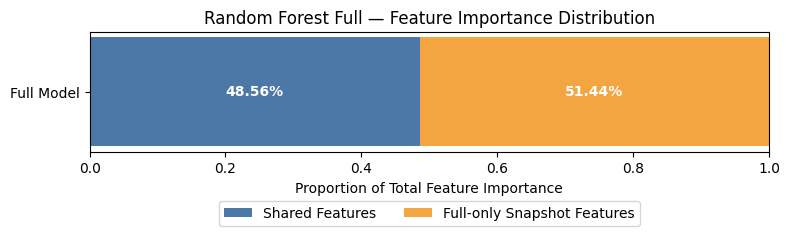

In [37]:
fig, ax = plt.subplots(figsize=(8, 2.8))

groups = [
    ("Shared Features", shared_total_importance, "#4C78A8"),
    ("Full-only Snapshot Features", snapshot_total_importance, "#F2A541")
]

left = 0

for label, value, color in groups:

    ax.barh(
        ["Full Model"],
        [value],
        left=left,
        color=color,
        label=label,
        height=0.45
    )

    if value >= 0.05:
        ax.text(
            left + value / 2,
            0,
            f"{value:.2%}",
            ha="center",
            va="center",
            color="white",
            fontweight="bold"
        )

    left += value

ax.set_xlim(0, 1)
ax.set_xlabel("Proportion of Total Feature Importance")

ax.set_title(
    "Random Forest Full — Feature Importance Distribution"
)

ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.35),
    ncol=2
)

plt.tight_layout()
plt.show()

**Observations:**

- The 10 additional customer snapshot features
  represent approximately 24.39% of the Full
  model's 41 prediction features.

- Seven snapshot features appear among the
  15 highest-ranked predictors.

- Despite representing less than one-quarter
  of the prediction features, the snapshot
  features account for approximately 51.44%
  of total impurity-based feature importance.

- The remaining 31 shared features collectively
  account for approximately 48.56%.

- The log-transformed number of associated
  customers is the most influential predictor,
  with an importance score of 0.2667.

- This feature alone accounts for approximately
  half of the combined snapshot feature importance.

- Recent payment history, order activity and
  refund behaviour also receive substantial
  importance within the Full model.

**Implications for Model Generalisation and Data Leakage**

The results indicate that the Full model assigns
substantial impurity-based importance to the
additional customer snapshot features.

This finding is consistent with the observed
improvements in validation recall, Average Precision
and ROC-AUC when these features are included.

However, the Full model also exhibits a more
pronounced training-validation performance gap.

If the snapshot features contain information
recorded after the order assessment date, the
model may depend on information unavailable
during actual fraud prediction.

Feature importance alone cannot confirm that
temporal data leakage has occurred.

The combined importance of 51.44% also does not
mean that snapshot features directly contribute
51.44% of the model's predictive performance.

Point-in-time feature availability must therefore
be verified before these features can be considered
suitable for production use.

Until this verification is completed, the Full
model remains exploratory, while the Safe model
is preferred for further production-oriented
assessment.

### 13.4 Interpretability Limitations

Several limitations must be considered when interpreting
Random Forest impurity-based feature importance.

**1. High-cardinality Feature Bias**

Impurity-based importance may favour numerical features
with many distinct values because they provide more
potential splitting opportunities.

As identified during the training data exploration,
several numerical predictors contain substantially
more distinct values than the binary predictors.

Their importance scores should therefore be interpreted
with caution.

**2. Correlated Predictors**

Correlated features may share similar predictive
information.

The forest may distribute importance across these
predictors or assign greater importance to one
predictor instead of another.

Consequently, a low individual importance score
does not necessarily indicate that a feature is
unimportant.

**3. Lack of Directional Interpretation**

Unlike Logistic Regression coefficients, impurity-based
importance scores do not indicate whether increasing
a feature increases or decreases fraud probability.

**4. Relative Rather Than Absolute Contribution**

Importance scores are normalised separately for
each fitted model.

Differences in importance between the Safe and Full
models do not directly measure changes in the absolute
predictive contribution of individual features.

**5. Potential Temporal Data Leakage**

High importance assigned to customer snapshot features
may indicate that the Full model relies on information
whose availability at prediction time is uncertain.

However, feature importance alone cannot establish
that temporal data leakage has occurred.

Point-in-time feature availability must be verified
before these predictors can be considered suitable
for production use.

**6. Fairness and Geographic Generalisation**

Several country-specific indicators receive
relatively high feature importance scores.

These predictors may reflect geographical
differences in observed fraud patterns, customer
behaviour or data distributions.

However, feature importance does not establish
that customers from a particular country are
inherently more likely to commit fraud.

Future evaluation should compare precision,
recall and false positive rates across countries
to identify potential performance disparities
and assess geographic generalisation.

**7. Potential Improvements**

Permutation importance on the validation dataset
could provide an additional assessment of how model
performance changes when individual features are
disrupted.

Grouped permutation importance may also help investigate
related or correlated predictors.

These methods are proposed as future improvements
rather than implemented in the current experiments.

Feature importance describes the behaviour of the
fitted model and should not be interpreted as
evidence of causal relationships.

## 14. Final Test Evaluation

### 14.1 Test Predictions

After completing model development and validation
analysis, both Random Forest versions are evaluated
using the unseen chronological test dataset.

The original model configurations and decision
threshold of 0.5 are retained.

The test dataset is not used for hyperparameter
tuning, threshold selection or further model
development.

This provides an independent assessment of model
performance on later orders.

In [38]:
# Verify the original decision threshold
assert THRESHOLD == 0.5

# Verify consistent test record alignment
assert X_test_safe.index.equals(y_test.index)
assert X_test_full.index.equals(y_test.index)

# Generate test probabilities using fitted models
y_test_prob_safe = model_safe.predict_proba(
    X_test_safe
)[:, 1]

y_test_prob_full = model_full.predict_proba(
    X_test_full
)[:, 1]

# Apply the original decision threshold
y_test_pred_safe = (
    y_test_prob_safe >= THRESHOLD
).astype(int)

y_test_pred_full = (
    y_test_prob_full >= THRESHOLD
).astype(int)

# Verify prediction lengths
assert len(y_test_prob_safe) == len(y_test)
assert len(y_test_prob_full) == len(y_test)

test_prediction_summary = pd.DataFrame({
    "Version": [
        "V1 - Safe",
        "V2 - Full"
    ],
    "Test Records": [
        len(X_test_safe),
        len(X_test_full)
    ],
    "Features": [
        X_test_safe.shape[1],
        X_test_full.shape[1]
    ],
    "Actual Fraud Cases": [
        y_test.sum(),
        y_test.sum()
    ],
    "Predicted Fraud Cases": [
        y_test_pred_safe.sum(),
        y_test_pred_full.sum()
    ],
    "Decision Threshold": [
        THRESHOLD,
        THRESHOLD
    ]
})

display(test_prediction_summary)

,Version,Test Records,Features,Actual Fraud Cases,Predicted Fraud Cases,Decision Threshold
0,V1 - Safe,144122,31,17835,5173,0.5
1,V2 - Full,144122,41,17835,10695,0.5


**Observations:**

- Both models generate predictions for all 144,122
  test records, containing 17,835 actual fraud cases.
- At the fixed threshold of 0.5, the Safe model flags
  5,173 orders as potentially fraudulent.
- The Full model flags 10,695 orders, representing
  5,522 additional flagged orders.
- Both models retain their original feature sets,
  hyperparameters and decision threshold.

Further evaluation is required to determine how many
flagged orders are correctly identified as fraudulent.

### 14.2 Test Evaluation and MLflow Logging

The final test metrics are calculated using the
team's shared classification evaluation utilities.

The results are recorded in the existing MLflow
runs for Version 1 and Version 2, ensuring that
each run contains its corresponding training,
validation and test results.

Test confusion matrices and precision-recall curves
are also stored as evaluation artifacts.

The original trained models, hyperparameters and
decision threshold remain unchanged.

No additional MLflow experiment runs are created
during final test evaluation.

In [39]:
# Ensure that no other MLflow run is active
assert mlflow.active_run() is None
assert THRESHOLD == 0.5
assert run_id_safe != run_id_full

# Verify that both existing runs are accessible
for run_id in [run_id_safe, run_id_full]:

    existing_run = mlflow.get_run(run_id)

    assert existing_run.info.lifecycle_stage == "active"

    print(
        "Existing run verified:",
        existing_run.info.run_name,
        run_id
    )

# Log V1 Safe test results to its existing run
with mlflow.start_run(run_id=run_id_safe):

    test_metrics_safe = log_classification_metrics(
        y_true=y_test,
        y_prob=y_test_prob_safe,
        threshold=THRESHOLD,
        split="test"
    )

    log_evaluation_artifacts(
        y_true=y_test,
        y_prob=y_test_prob_safe,
        feature_names=X_test_safe.columns,
        threshold=THRESHOLD,
        split="test"
    )

    mlflow.log_param(
        "test_records",
        len(y_test)
    )

# Log V2 Full test results to its existing run
with mlflow.start_run(run_id=run_id_full):

    test_metrics_full = log_classification_metrics(
        y_true=y_test,
        y_prob=y_test_prob_full,
        threshold=THRESHOLD,
        split="test"
    )

    log_evaluation_artifacts(
        y_true=y_test,
        y_prob=y_test_prob_full,
        feature_names=X_test_full.columns,
        threshold=THRESHOLD,
        split="test"
    )

    mlflow.log_param(
        "test_records",
        len(y_test)
    )

print("\nFinal test evaluation logging completed.")
print("Safe Run ID:", run_id_safe)
print("Full Run ID:", run_id_full)
print("No additional MLflow runs were created.")

Existing run verified: abby_random_forest_safe_v1 d4bf142387a64ead914ac4d9124ceb87
Existing run verified: abby_random_forest_full_v2 2f540eb6b80a4bb5b276a59ca3ced542
🏃 View run abby_random_forest_safe_v1 at: http://127.0.0.1:5004/#/experiments/1/runs/d4bf142387a64ead914ac4d9124ceb87
🧪 View experiment at: http://127.0.0.1:5004/#/experiments/1
🏃 View run abby_random_forest_full_v2 at: http://127.0.0.1:5004/#/experiments/1/runs/2f540eb6b80a4bb5b276a59ca3ced542
🧪 View experiment at: http://127.0.0.1:5004/#/experiments/1

Final test evaluation logging completed.
Safe Run ID: d4bf142387a64ead914ac4d9124ceb87
Full Run ID: 2f540eb6b80a4bb5b276a59ca3ced542
No additional MLflow runs were created.


### 14.3 Final Test Performance Comparison

The final test performance of both Random Forest
versions is compared using six evaluation metrics.

Precision remains the primary business metric,
while recall is examined to determine whether the
models provide sufficient fraud detection coverage.

Average Precision and ROC-AUC are also considered
to assess ranking performance.

Both models are evaluated using the same unseen
test records and the original decision threshold
of 0.5.

The Full model remains exploratory due to the
uncertain point-in-time availability of its
additional customer snapshot features.

In [40]:
metric_labels = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-score",
    "PR-AUC (Average Precision)",
    "ROC-AUC"
]

test_comparison = pd.DataFrame({
    "Metric": metric_labels,
    "V1 - Safe": [
        test_metrics_safe[f"test_{m}"]
        for m in metric_names
    ],
    "V2 - Full": [
        test_metrics_full[f"test_{m}"]
        for m in metric_names
    ]
})

test_comparison["Difference (Full - Safe)"] = (
    test_comparison["V2 - Full"] -
    test_comparison["V1 - Safe"]
)

display(test_comparison.round(4))

,Metric,V1 - Safe,V2 - Full,Difference (Full - Safe)
0,Accuracy,0.8797,0.8832,0.0035
1,Precision,0.5484,0.5470,-0.0014
2,Recall,0.1591,0.3280,0.1689
3,F1-score,0.2466,0.4101,0.1635
4,PR-AUC (Average Precision),0.4177,0.5076,0.0899
5,ROC-AUC,0.8035,0.8711,0.0676


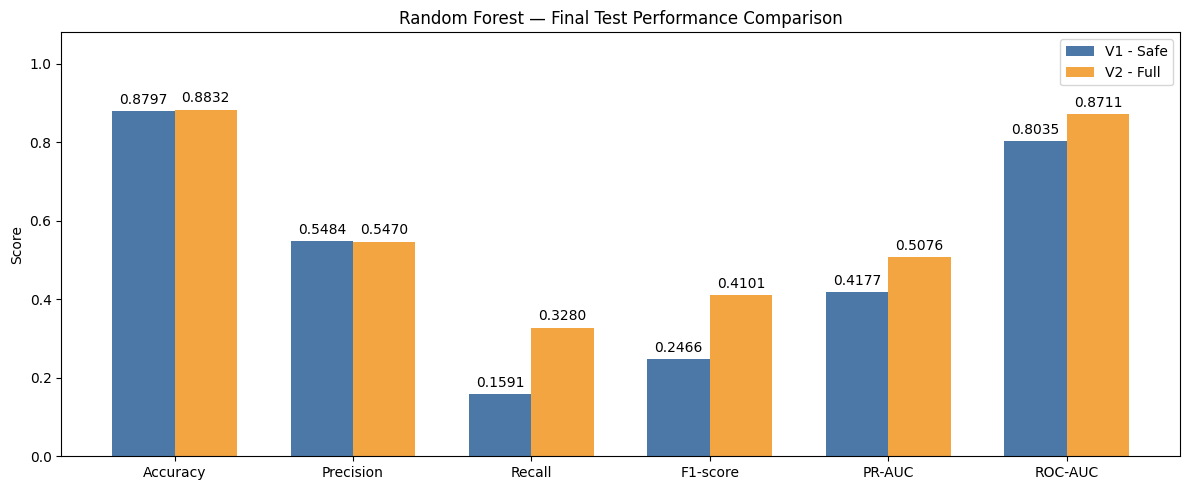

In [41]:
fig, ax = plt.subplots(figsize=(12, 5))

positions = np.arange(len(test_comparison))
width = 0.35

bars_safe = ax.bar(
    positions - width / 2,
    test_comparison["V1 - Safe"],
    width,
    label="V1 - Safe",
    color="#4C78A8"
)

bars_full = ax.bar(
    positions + width / 2,
    test_comparison["V2 - Full"],
    width,
    label="V2 - Full",
    color="#F2A541"
)

ax.bar_label(
    bars_safe,
    fmt="%.4f",
    padding=3
)

ax.bar_label(
    bars_full,
    fmt="%.4f",
    padding=3
)

ax.set_xticks(positions)

ax.set_xticklabels([
    "Accuracy",
    "Precision",
    "Recall",
    "F1-score",
    "PR-AUC",
    "ROC-AUC"
])

ax.set_title(
    "Random Forest — Final Test Performance Comparison"
)

ax.set_ylabel("Score")
ax.set_ylim(0, 1.08)
ax.legend()

plt.tight_layout()
plt.show()

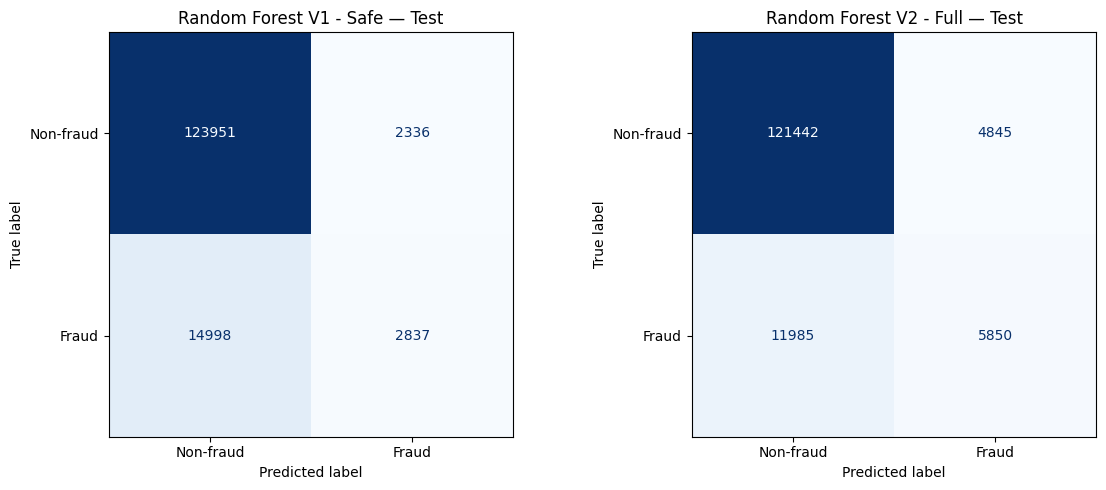

In [42]:
cm_test_safe = confusion_matrix(
    y_test,
    y_test_pred_safe,
    labels=[0, 1]
)

cm_test_full = confusion_matrix(
    y_test,
    y_test_pred_full,
    labels=[0, 1]
)

tn_test_safe, fp_test_safe, fn_test_safe, tp_test_safe = (
    cm_test_safe.ravel()
)

tn_test_full, fp_test_full, fn_test_full, tp_test_full = (
    cm_test_full.ravel()
)

fig, axes = plt.subplots(
    1, 2,
    figsize=(12, 5)
)

for ax, cm, version in [
    (axes[0], cm_test_safe, "V1 - Safe"),
    (axes[1], cm_test_full, "V2 - Full")
]:

    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Non-fraud", "Fraud"]
    ).plot(
        ax=ax,
        cmap="Blues",
        values_format="d",
        colorbar=False
    )

    ax.set_title(
        f"Random Forest {version} — Test"
    )

plt.tight_layout()
plt.show()

In [43]:
test_business_comparison = pd.DataFrame({
    "Measurement": [
        "True Negatives",
        "False Positives",
        "False Negatives",
        "True Positives",
        "Flagged Orders"
    ],
    "V1 - Safe": [
        tn_test_safe,
        fp_test_safe,
        fn_test_safe,
        tp_test_safe,
        tp_test_safe + fp_test_safe
    ],
    "V2 - Full": [
        tn_test_full,
        fp_test_full,
        fn_test_full,
        tp_test_full,
        tp_test_full + fp_test_full
    ]
})

test_business_comparison["Difference (Full - Safe)"] = (
    test_business_comparison["V2 - Full"] -
    test_business_comparison["V1 - Safe"]
)

display(test_business_comparison)

,Measurement,V1 - Safe,V2 - Full,Difference (Full - Safe)
0,True Negatives,123951,121442,-2509
1,False Positives,2336,4845,2509
2,False Negatives,14998,11985,-3013
3,True Positives,2837,5850,3013
4,Flagged Orders,5173,10695,5522


### Final Test Performance Observations

**1. Predictive Performance**

- The Safe model achieves test precision of 54.84%,
  recall of 15.91% and an F1-score of 0.2466.
- The Full model achieves test precision of 54.70%,
  recall of 32.80% and an F1-score of 0.4101.
- The Full model outperforms the Safe model in five
  of the six evaluation metrics.
- Average Precision increases from 0.4177 to 0.5076,
  while ROC-AUC increases from 0.8035 to 0.8711.
- However, the Safe model retains slightly higher
  precision, with a difference of approximately
  0.14 percentage points.

**2. Business Impact**

Compared with the Safe model, the Full model:

- Correctly detects 3,013 additional fraudulent orders.
- Incorrectly flags 2,509 additional legitimate orders.
- Reduces false negatives from 14,998 to 11,985.
- Increases flagged orders from 5,173 to 10,695.

Although the Full model provides greater detection
coverage, the increased number of flagged orders may
substantially increase investigation workload.

**3. Stakeholder Requirements**

Both models achieve test precision of approximately
55%, meaning that approximately 45% of flagged
orders are legitimate.

This raises concerns regarding unnecessary
investigations and the potential impact on
legitimate customers.

Both models also miss a substantial proportion
of actual fraudulent orders at the current
decision threshold.

Consequently, neither model can be confirmed to
fully satisfy the stakeholder's requirement of
high precision with reasonable recall.

**4. Production Suitability**

Although the Full model achieves stronger overall
test performance, its additional customer snapshot
features have uncertain point-in-time availability.

The Safe model is therefore preferred for further
production-oriented assessment, subject to additional
feature verification and performance improvements.

The Full model remains an exploratory experiment.

### 14.4 Generalisation Across Data Splits

Training, validation and test performance are
compared to assess model stability across different
chronological periods.

This comparison helps identify potential overfitting,
performance deterioration and changes in predictive
effectiveness on unseen data.

Differences in fraud prevalence across the three
splits are considered when interpreting the results.

The test results are used for final assessment
rather than further model or threshold optimisation.

In [44]:
generalisation_results = []

for version, metrics_by_split in [
    (
        "V1 - Safe",
        [
            ("train", train_metrics_safe),
            ("val", val_metrics_safe),
            ("test", test_metrics_safe)
        ]
    ),
    (
        "V2 - Full",
        [
            ("train", train_metrics_full),
            ("val", val_metrics_full),
            ("test", test_metrics_full)
        ]
    )
]:

    for split, metrics in metrics_by_split:

        generalisation_results.append({
            "Version": version,
            "Split": {
                "train": "Train",
                "val": "Validation",
                "test": "Test"
            }[split],
            "Accuracy": metrics[f"{split}_accuracy"],
            "Precision": metrics[f"{split}_precision"],
            "Recall": metrics[f"{split}_recall"],
            "F1-score": metrics[f"{split}_f1"],
            "PR-AUC (AP)": metrics[f"{split}_pr_auc"],
            "ROC-AUC": metrics[f"{split}_roc_auc"]
        })

generalisation_summary = pd.DataFrame(
    generalisation_results
)

display(generalisation_summary.round(4))

,Version,Split,Accuracy,Precision,Recall,F1-score,PR-AUC (AP),ROC-AUC
0,V1 - Safe,Train,0.9097,0.7398,0.1704,0.2770,0.4616,0.8245
1,V1 - Safe,Validation,0.8733,0.6853,0.1237,0.2096,0.5289,0.8554
2,V1 - Safe,Test,0.8797,0.5484,0.1591,0.2466,0.4177,0.8035
3,V2 - Full,Train,0.9238,0.7279,0.3975,0.5142,0.6520,0.9296
4,V2 - Full,Validation,0.8789,0.6231,0.2734,0.3801,0.5636,0.8962
5,V2 - Full,Test,0.8832,0.5470,0.3280,0.4101,0.5076,0.8711


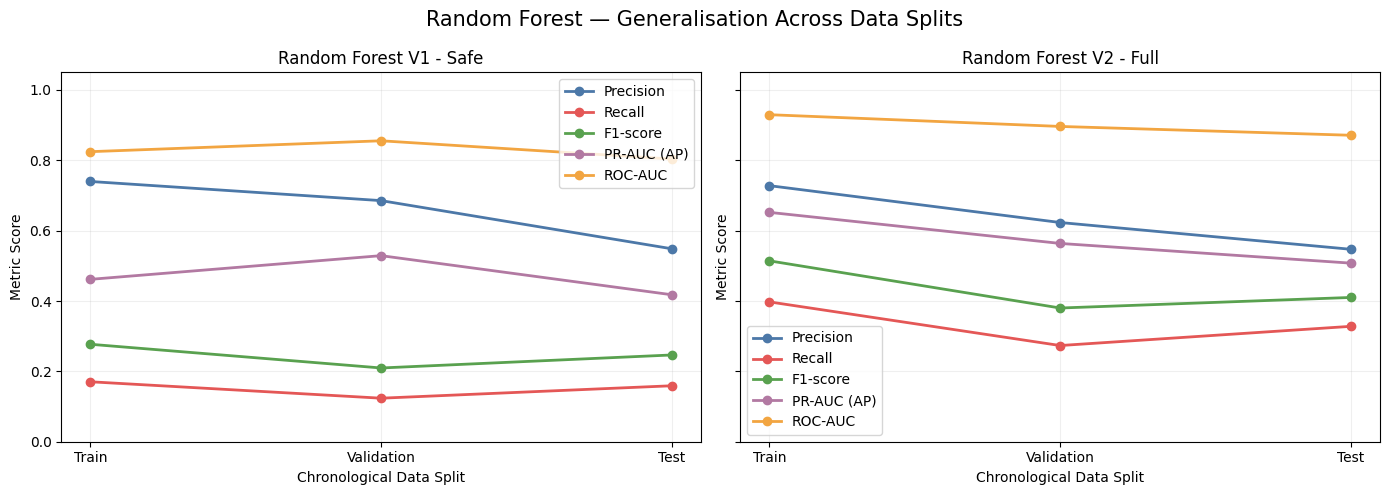

In [45]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 5),
    sharey=True
)

metrics_to_plot = [
    ("Precision", "#4C78A8"),
    ("Recall", "#E45756"),
    ("F1-score", "#59A14F"),
    ("PR-AUC (AP)", "#B279A2"),
    ("ROC-AUC", "#F2A541")
]

for ax, version in zip(
    axes,
    ["V1 - Safe", "V2 - Full"]
):

    version_results = generalisation_summary[
        generalisation_summary["Version"] == version
    ]

    for metric, color in metrics_to_plot:

        ax.plot(
            version_results["Split"],
            version_results[metric],
            marker="o",
            linewidth=2,
            label=metric,
            color=color
        )

    ax.set_title(f"Random Forest {version}")
    ax.set_xlabel("Chronological Data Split")
    ax.set_ylabel("Metric Score")
    ax.set_ylim(0, 1.05)
    ax.legend(loc="best")
    ax.grid(alpha=0.2)

fig.suptitle(
    "Random Forest — Generalisation Across Data Splits",
    fontsize=15
)

plt.tight_layout()
plt.show()

In [46]:
gap_results = []

for version, train_metrics, val_metrics, test_metrics in [
    (
        "V1 - Safe",
        train_metrics_safe,
        val_metrics_safe,
        test_metrics_safe
    ),
    (
        "V2 - Full",
        train_metrics_full,
        val_metrics_full,
        test_metrics_full
    )
]:

    for metric, label in zip(
        metric_names,
        metric_labels
    ):

        gap_results.append({
            "Version": version,
            "Metric": label,
            "Validation - Train": (
                val_metrics[f"val_{metric}"] -
                train_metrics[f"train_{metric}"]
            ),
            "Test - Validation": (
                test_metrics[f"test_{metric}"] -
                val_metrics[f"val_{metric}"]
            ),
            "Test - Train": (
                test_metrics[f"test_{metric}"] -
                train_metrics[f"train_{metric}"]
            )
        })

generalisation_gap = pd.DataFrame(gap_results)

display(generalisation_gap.round(4))

,Version,Metric,Validation - Train,Test - Validation,Test - Train
0,V1 - Safe,Accuracy,-0.0364,0.0064,-0.0300
1,V1 - Safe,Precision,-0.0544,-0.1369,-0.1913
2,V1 - Safe,Recall,-0.0467,0.0353,-0.0113
3,V1 - Safe,F1-score,-0.0674,0.0370,-0.0304
4,V1 - Safe,PR-AUC (Average Precision),0.0673,-0.1112,-0.0438
5,V1 - Safe,ROC-AUC,0.0310,-0.0519,-0.0210
6,V2 - Full,Accuracy,-0.0449,0.0043,-0.0405
7,V2 - Full,Precision,-0.1047,-0.0761,-0.1809
8,V2 - Full,Recall,-0.1240,0.0546,-0.0695
9,V2 - Full,F1-score,-0.1341,0.0300,-0.1041


### Generalisation Observations

**1. Safe Model Generalisation**

- Precision decreases from 0.7398 during training
  to 0.6853 during validation and 0.5484 during
  final test evaluation.
- Test recall increases relative to validation
  recall but remains below training recall.
- Test Average Precision and ROC-AUC decrease to
  0.4177 and 0.8035, respectively.
- The relatively small training-test ROC-AUC gap
  of 0.0210 indicates that the model retains
  substantial ranking capability on later orders.

Nevertheless, the decline in precision indicates
that the model's classification reliability
deteriorates across chronological periods.

**2. Full Model Generalisation**

- All final test metrics are lower than their
  corresponding training metrics.
- Average Precision decreases from 0.6520 during
  training to 0.5076 during final test evaluation.
- ROC-AUC decreases from 0.9296 to 0.8711.
- The Full model exhibits larger training-test
  performance gaps in recall, F1-score, Average
  Precision and ROC-AUC than the Safe model.

These results indicate greater potential
generalisation concerns for the Full model.

**3. Overfitting and Underfitting Assessment**

The larger ranking performance gaps observed in
the Full model suggest a greater potential risk
of overfitting.

However, chronological distribution changes and
differences in feature availability may also
contribute to the observed performance deterioration.

Both models demonstrate limited training recall at
the fixed decision threshold of 0.5, particularly
the Safe model.

However, the threshold sensitivity analysis shows
that recall can be substantially improved without
retraining the classifier.

Therefore, low recall alone does not establish
that either model is underfitting.

**4. Temporal Distribution Changes**

Fraud prevalence differs across the chronological
data splits:

- Training: approximately 10.15%.
- Validation: approximately 13.58%.
- Test: approximately 12.37%.

Differences in fraud prevalence and customer
behaviour may influence classification metrics
and Average Precision.

The observed performance changes suggest that
temporal distribution shifts should be investigated,
although their exact causes have not been established.

**5. Overall Assessment**

The Safe model demonstrates relatively smaller
training-test ranking performance gaps but still
requires improvements in classification precision
and fraud detection coverage.

The Full model provides stronger overall predictive
performance but exhibits larger generalisation gaps
and unresolved temporal data leakage concerns.

These findings motivate further threshold optimisation,
hyperparameter tuning, point-in-time feature validation
and ongoing model performance monitoring.

The test results are retained for final evaluation
and are not used to modify the trained models or
decision threshold.

## 15. Further Potential Improvements

Although both Random Forest versions were successfully
trained and evaluated, several improvements could be
considered in future iterations.

The following recommendations are based on the
validation experiments, feature importance analysis
and final generalisation assessment.

### 15.1 Decision Threshold Optimisation

The validation threshold sensitivity analysis
demonstrates that reducing the decision threshold
can substantially increase fraud detection coverage
without retraining the model.

For the Safe model, reducing the threshold from
0.5 to 0.25 increases validation recall from
12.37% to 40.66%.

However, precision decreases from 68.53% to 60.18%,
and the number of false positives increases.

A suitable operating threshold could be selected
by maximising recall while maintaining a
stakeholder-approved minimum precision level.

Investigation capacity and the business costs of
false positives and false negatives should also
be considered.

Threshold selection must be performed using
validation data rather than the final test dataset.

### 15.2 Class Weighting

The training dataset contains approximately 10.15%
fraudulent orders, indicating class imbalance.

The current models use class_weight=None.

Future experiments could investigate:

- class_weight="balanced"
- class_weight="balanced_subsample"
- Custom class weights reflecting business costs.

Class weighting may increase the model's sensitivity
to fraudulent orders and improve recall.

However, it may also increase false positives and
reduce precision.

Its effectiveness should therefore be assessed using
precision-focused validation criteria.

### 15.3 Hyperparameter Tuning

Both Random Forest versions use 50 trees and a
maximum tree depth of 15.

All trees reach the configured maximum depth,
indicating that the depth restriction actively
limits tree growth.

Future experiments could investigate:

- n_estimators: 50, 100 and 200.
- max_depth: 10, 15 and 20.
- min_samples_leaf: 10, 20 and 50.
- max_features: "sqrt", "log2" and selected fractions.

Shallower trees and larger minimum leaf sizes
may reduce overfitting, while deeper trees may
capture more complex fraud patterns.

Increasing the number of trees may improve prediction
stability but increase training time and model size.

The current min_samples_split value of 10 is
effectively redundant because min_samples_leaf=20
requires at least 40 samples for a valid binary split.

Future tuning should therefore prioritise meaningful
complexity controls and avoid redundant combinations.

Chronological validation should be retained throughout
hyperparameter selection.

### 15.4 Feature Selection and Interpretability

The Safe model assigns substantial importance to
account age, order value and country-specific indicators.

Impurity-based feature importance may favour predictors
with many possible splitting points.

Validation-based permutation importance could provide
additional evidence of predictive contribution.

Constant and consistently uninformative predictors
could also be evaluated for removal to simplify the
feature set.

However, feature removal should be supported by
validation experiments rather than importance
scores alone.

Performance across different countries should also
be investigated to identify potential disparities
in precision, recall and false positive rates.

### 15.5 Point-in-Time Customer Features

The Full model assigns approximately 51.44% of its
total impurity-based feature importance to the 10
additional customer snapshot features.

These results demonstrate the potential predictive
value of customer behavioural information.

Future improvements could reconstruct customer
features using only information available before
each order assessment.

For example:

- Previous 50-day refund and cancellation activity.
- Previous 50-day order and payment activity.
- Customer associations known at assessment time.

Feature calculation windows and data availability
must be verified to prevent future information
from entering the training data.

Prohibited features such as refund_value must
remain excluded.

This would allow potentially useful behavioural
features to be incorporated while reducing
temporal leakage risk.

### 15.6 Model Monitoring and Retraining

Both models demonstrate declining precision across
the chronological training, validation and test periods.

Future monitoring should track:

- Precision and recall.
- Average Precision and ROC-AUC.
- Fraud prevalence.
- Feature distribution changes.
- False positive investigation workload.

Automated retraining could help maintain predictive
effectiveness as customer behaviour and fraud patterns
change over time.

Retraining should use the team's shared data
processing, evaluation and MLflow tracking utilities.

The computational cost of Random Forest should
also be considered when integrating the models into
the automated retraining workflow under PBI 5.

### 15.7 Improvement Prioritisation

The recommended order of future improvements is:

1. Verify point-in-time feature availability.
2. Establish acceptable precision and recall
   requirements with the stakeholder.
3. Optimise the decision threshold using
   chronological validation data.
4. Investigate class weighting and hyperparameter
   optimisation.
5. Monitor performance and integrate automated
   retraining.

These improvements are proposed for future iterations.

Threshold sensitivity analysis has been conducted,
but no additional model configuration or alternative
operating threshold has been adopted in the current
experiments.

The original trained models and final test results
remain unchanged.

## 16. Model Reproducibility and Verification

### 16.1 Model Reload and Prediction Verification

Both trained Random Forest classifiers are reloaded
from the MLflow tracking server using their logged
model URIs.

The reloaded models are used to generate fraud
probabilities and binary predictions on the test
dataset.

These predictions are compared with the original
model outputs to verify that model serialisation
and retrieval preserve predictive behaviour.

The feature schema and trained model configuration
are also checked to ensure consistency.

This verification supports reliable model management,
reproducibility and future automated retraining.

No additional model training or experiment runs
are required.

In [47]:
import mlflow.sklearn

# Reload both models using their existing model URIs
loaded_model_safe = mlflow.sklearn.load_model(
    model_info_safe.model_uri
)

loaded_model_full = mlflow.sklearn.load_model(
    model_info_full.model_uri
)

verification_results = []

for version, original_model, loaded_model, X_test_version, original_prob in [
    (
        "V1 - Safe",
        model_safe,
        loaded_model_safe,
        X_test_safe,
        y_test_prob_safe
    ),
    (
        "V2 - Full",
        model_full,
        loaded_model_full,
        X_test_full,
        y_test_prob_full
    )
]:

    # Verify model type, configuration and feature schema
    assert isinstance(
        loaded_model,
        RandomForestClassifier
    )

    assert (
        loaded_model.get_params()
        == original_model.get_params()
    )

    assert np.array_equal(
        loaded_model.feature_names_in_,
        X_test_version.columns.to_numpy()
    )

    assert np.array_equal(
        loaded_model.classes_,
        original_model.classes_
    )

    # Generate probabilities using the reloaded model
    loaded_prob = loaded_model.predict_proba(
        X_test_version
    )[:, 1]

    # Apply the original decision threshold
    original_pred = (
        original_prob >= THRESHOLD
    ).astype(int)

    loaded_pred = (
        loaded_prob >= THRESHOLD
    ).astype(int)

    # Compare probability outputs
    max_difference = np.max(
        np.abs(original_prob - loaded_prob)
    )

    exact_probability_match = np.array_equal(
        original_prob,
        loaded_prob
    )

    probability_match = np.allclose(
        original_prob,
        loaded_prob,
        rtol=0,
        atol=1e-12
    )

    prediction_match = np.array_equal(
        original_pred,
        loaded_pred
    )

    matching_predictions = np.sum(
        original_pred == loaded_pred
    )

    verification_results.append({
        "Version": version,
        "Test Records": len(X_test_version),
        "Features": X_test_version.shape[1],
        "Number of Trees": len(loaded_model.estimators_),
        "Exact Probability Match": exact_probability_match,
        "Probability Match (Tolerance)": probability_match,
        "Maximum Probability Difference": max_difference,
        "Matching Predictions": matching_predictions,
        "Prediction Match": prediction_match,
        "Status": (
            "Passed"
            if probability_match and prediction_match
            else "Failed"
        )
    })

verification_summary = pd.DataFrame(
    verification_results
)

display(verification_summary)

assert verification_summary["Status"].eq("Passed").all()

print("Model reload verification: Passed")

,Version,Test Records,Features,Number of Trees,Exact Probability Match,Probability Match (Tolerance),Maximum Probability Difference,Matching Predictions,Prediction Match,Status
0,V1 - Safe,144122,31,50,False,True,3.330669e-16,144122,True,Passed
1,V2 - Full,144122,41,50,False,True,4.440892e-16,144122,True,Passed


Model reload verification: Passed


**Observations:**

- Both Random Forest classifiers were successfully
  reloaded from the MLflow tracking server.

- The reloaded models retained their original
  hyperparameter configurations, feature schemas,
  class labels and number of decision trees.

- Both models generated predictions for all
  144,122 test records.

- Exact probability equality was not achieved
  due to negligible floating-point differences.

- The maximum probability differences were
  approximately 3.33e-16 for the Safe model and
  4.44e-16 for the Full model.

- Both differences are substantially below the
  numerical tolerance of 1e-12.

- All 144,122 binary predictions matched their
  corresponding original predictions for each model.

- Both models achieved 100% classification agreement
  and passed model reload verification.

The negligible numerical differences are consistent
with floating-point arithmetic during parallel
Random Forest prediction.

The results demonstrate that model serialisation
and retrieval preserve predictive behaviour within
the specified numerical tolerance.

This supports reliable model management and future
integration into the automated retraining workflow.

### 16.2 MLflow Run Completeness Verification

The MLflow tracking records are inspected to verify
that both model versions contain their required
evaluation metrics, model identifiers and artifacts.

Each experiment run is expected to contain:

- Six training evaluation metrics.
- Six validation evaluation metrics.
- Six final test evaluation metrics.
- Model hyperparameters and training configuration.
- A valid logged model URI.
- Validation and test confusion matrices.
- Validation and test precision-recall curves.
- Prediction feature metadata.

The recorded evaluation metric values are compared
with the corresponding notebook results.

This verification supports consistent experiment
tracking, subsequent model comparison and model
registry operations.

In [48]:
client = mlflow.MlflowClient()

# Define required evaluation metrics
required_metrics = {
    f"{split}_{metric}"
    for split in ["train", "val", "test"]
    for metric in metric_names
}

# Define required artifacts
required_artifacts = {
    "evaluation/val_confusion_matrix.png",
    "evaluation/val_pr_curve.png",
    "evaluation/test_confusion_matrix.png",
    "evaluation/test_pr_curve.png",
    "metadata/features.json",
}

# Recursively collect artifact paths
def collect_artifact_paths(run_id, path=None):

    paths = set()

    for artifact in client.list_artifacts(
        run_id, path
    ):

        if artifact.is_dir:
            paths.update(
                collect_artifact_paths(
                    run_id,
                    artifact.path
                )
            )
        else:
            paths.add(artifact.path)

    return paths


run_verification = []

for version, run_id, model_info, expected_metrics in [
    (
        "V1 - Safe",
        run_id_safe,
        model_info_safe,
        {
            **train_metrics_safe,
            **val_metrics_safe,
            **test_metrics_safe
        }
    ),
    (
        "V2 - Full",
        run_id_full,
        model_info_full,
        {
            **train_metrics_full,
            **val_metrics_full,
            **test_metrics_full
        }
    )
]:

    # Retrieve existing MLflow run
    stored_run = client.get_run(run_id)

    logged_metrics = set(
        stored_run.data.metrics.keys()
    )

    artifact_paths = collect_artifact_paths(
        run_id
    )

    # Identify missing records
    missing_metrics = (
        required_metrics - logged_metrics
    )

    missing_artifacts = (
        required_artifacts - artifact_paths
    )

    # Verify run status and completeness
    assert stored_run.info.status == "FINISHED"

    assert stored_run.info.lifecycle_stage == "active"

    assert not missing_metrics, missing_metrics
    assert not missing_artifacts, missing_artifacts

    # Verify recorded metric values
    metric_values_match = all(
        np.isclose(
            stored_run.data.metrics[metric],
            expected_metrics[metric],
            rtol=0,
            atol=1e-12
        )
        for metric in required_metrics
    )

    assert metric_values_match

    # Verify recorded model URI
    logged_model_uri = stored_run.data.tags.get(
        "logged_model_uri"
    )

    model_uri_match = (
        logged_model_uri == model_info.model_uri
    )

    assert model_uri_match

    # Verify model hyperparameters
    missing_parameters = (
        set(MODEL_PARAMS)
        - set(stored_run.data.params)
    )

    assert not missing_parameters, missing_parameters

    # Summarise verification results
    run_verification.append({
        "Version": version,
        "Run ID": run_id,
        "Run Status": stored_run.info.status,
        "Evaluation Metrics": (
            f"{len(required_metrics & logged_metrics)}"
            f"/{len(required_metrics)}"
        ),
        "Metric Values Match": metric_values_match,
        "Required Artifacts": (
            f"{len(required_artifacts & artifact_paths)}"
            f"/{len(required_artifacts)}"
        ),
        "Model URI Match": model_uri_match,
        "Hyperparameters Present": True,
        "Status": "Passed"
    })

run_verification_summary = pd.DataFrame(
    run_verification
)

display(run_verification_summary)

print("Both MLflow runs passed completeness verification.")

,Version,Run ID,Run Status,Evaluation Metrics,Metric Values Match,Required Artifacts,Model URI Match,Hyperparameters Present,Status
0,V1 - Safe,d4bf142387a64ead914ac4d9124ceb87,FINISHED,18/18,True,5/5,True,True,Passed
1,V2 - Full,2f540eb6b80a4bb5b276a59ca3ced542,FINISHED,18/18,True,5/5,True,True,Passed


Both MLflow runs passed completeness verification.


**Observations:**

- Both MLflow runs have a FINISHED status and
  remain active experiment records.

- All 18 required classification metrics were
  successfully recorded for each model version,
  covering training, validation and testing.

- All recorded evaluation metric values match
  their corresponding notebook results within
  the specified numerical tolerance.

- All five required evaluation and feature metadata
  artifact paths are present in each experiment run.

- Both recorded model URIs match the corresponding
  logged model identifiers.

- All required model hyperparameter keys are present.

- The existing experiment runs were reused when
  logging final test results, avoiding unnecessary
  duplicate runs.

The results demonstrate consistent experiment
tracking and provide the necessary evaluation
records for subsequent model comparison and
registry operations.

The artifact verification confirms the presence
of the required file paths rather than validating
their individual file contents.

This verification was conducted on the persistent
local MLflow server.

Shared AWS tracking verification and automated
retraining integration remain subsequent tasks.

## 17. Conclusion

This notebook successfully developed and evaluated
two Random Forest versions for SP-buy fraud detection
using the team's shared feature datasets and
chronological data split.

Both versions use identical configured hyperparameters
and a fixed decision threshold of 0.5, allowing the
observed impact of additional customer snapshot
features to be investigated.

### 17.1 Model Performance Summary

| Metric | V1 - Safe | V2 - Full |
|---|---:|---:|
| Number of features | 31 | 41 |
| Number of trees | 50 | 50 |
| Maximum tree depth | 15 | 15 |
| Training time (s) | 11.0171 | 15.7375 |
| Total tree nodes | 109574 | 161830 |
| Validation accuracy | 0.8733 | 0.8789 |
| Validation precision | 0.6853 | 0.6231 |
| Validation recall | 0.1237 | 0.2734 |
| Validation F1-score | 0.2096 | 0.3801 |
| Validation Average Precision | 0.5289 | 0.5636 |
| Validation ROC-AUC | 0.8554 | 0.8962 |
| Test accuracy | 0.8797 | 0.8832 |
| Test precision | 0.5484 | 0.5470 |
| Test recall | 0.1591 | 0.3280 |
| Test F1-score | 0.2466 | 0.4101 |
| Test Average Precision | 0.4177 | 0.5076 |
| Test ROC-AUC | 0.8035 | 0.8711 |

### 17.2 Business Assessment

The Safe model achieves higher precision on both
the validation and test datasets, aligning more
closely with the stakeholder's priority of minimising
unnecessary investigations of legitimate customers.

However, its limited recall reduces its effectiveness
in detecting fraudulent orders.

The Full model achieves stronger recall, F1-score,
Average Precision and ROC-AUC across both evaluation
datasets.

On the final test dataset, the Full model correctly
detects 3,013 additional fraudulent orders compared
with the Safe model, but incorrectly flags 2,509
additional legitimate orders.

Both models achieve test precision of approximately
55%, raising concerns regarding unnecessary
investigations and classification reliability.

Neither version can be confirmed to fully satisfy
the stakeholder's requirement of high precision
with reasonable recall at the fixed threshold of 0.5.

### 17.3 Recommended Model

Among the two Random Forest versions, the Safe
model is recommended as the more appropriate candidate
for further production-oriented development.

This recommendation is based on:

- Higher validation precision.
- Lower known temporal data leakage risk.
- Smaller training-test ranking performance gaps.
- Lower model complexity and fitting time.
- Potential improvements through validation-based
  decision threshold optimisation.

Although the Full model achieves stronger overall
predictive performance, approximately 51.44% of its
total impurity-based feature importance is assigned
to the 10 additional customer snapshot features.

The availability of these features at order
assessment time has not been established.

Therefore, the Full model remains an exploratory
experiment rather than an eligible production
candidate unless point-in-time feature availability
can be verified.

The Safe model also requires further feature
availability verification and performance improvements
before production deployment.

The final Champion Model should be selected after
comparing all eligible team models against the
stakeholder's business requirements.

### 17.4 Future Improvements

Validation-based decision threshold optimisation
is recommended as a priority for improving the
Safe model's classification performance.

The threshold sensitivity analysis demonstrates
that reducing the threshold from 0.5 to 0.25
increases validation recall from 12.37% to 40.66%.

However, precision decreases from 68.53% to 60.18%,
and investigation workload increases.

The final operating threshold should therefore
be agreed with the stakeholder based on acceptable
precision, recall, investigation capacity and
classification error costs.

Additional improvements include:

- Class weighting to address class imbalance.
- Hyperparameter tuning to control model complexity
  and improve generalisation.
- Validation-based permutation importance.
- Geographic performance and fairness assessment.
- Point-in-time customer behavioural features.
- Ongoing model monitoring and automated retraining.

These improvements should be evaluated using
chronological validation data without using the
final test dataset for model optimisation.

### 17.5 MLOps Readiness

Both Random Forest versions were successfully
trained, evaluated and recorded in MLflow with
their hyperparameters, evaluation metrics,
trained classifiers and evaluation artifacts.

Model reload verification demonstrated numerically
equivalent fraud probabilities within the specified
tolerance and identical binary predictions for all
144,122 test records for each model version.

Both experiment runs passed completeness verification,
including:

- 18 of 18 required classification metrics per run.
- Matching recorded evaluation metric values.
- Five of five required artifact paths per run.
- Matching logged model URIs.
- Presence of all required hyperparameter keys.

These results demonstrate successful local experiment
tracking and model retrieval.

The experiments provide a reproducible foundation
for subsequent team model comparison, model registry
operations and automated retraining integration.

Shared AWS MLflow integration and standardised Python
training scripts remain subsequent development tasks.